# Sparse variational GP (SVGP) twin from scratch

This notebook builds RADP's **SVGP digital twin** of a radio network from raw simulator output. It measures how good that twin is, and puts it side by side with the exact-GP **Bayesian Digital Twin (BDT)** on the same data and split as [bayesian_digital_twin.ipynb](bayesian_digital_twin.ipynb).

**The twin in one paragraph.** `SVGPDigitalTwin` is a *sparse variational* Gaussian process per cell. It learns the cell's received power `cell_rxpwr_dbm` from the same three features as the BDT:
- `log_distance`: distance from the site, on a log scale
- `relative_bearing`: angle away from the antenna's boresight
- `cell_el_deg`: the cell's electrical tilt

The kernel is the same scaled RBF with ARD. Three things differ from the exact GP:
- **Inducing points.** Each cell's function is summarised by M inducing points (500 by default), placed by k-means++ and then learned.
- **Mini-batches.** Training maximises a variational lower bound (the ELBO) on mini-batches. The variational distribution takes natural-gradient steps; the kernel and noise take Adam steps.
- **One model for all cells.** All cells train together in one batched model.

The cost of a training step depends on the batch size and M, **not on the number of rows**. That is the reason to use it: the exact GP's cost grows roughly with the cube of the rows per cell.

**What you will see**

| § | Question | Headline KPI / visual |
|---|---|---|
| 1–3 | The network, the ground truth, and the features the engine builds | topology, per-cell footprints, RSRP per tilt, path-loss curve, antenna pattern |
| 4–5 | Training: why the defaults underfit here, and the fix | early-stopping misfires, MAE / ±2σ vs optimiser steps, loss curves, "watch it learn" |
| 6 | What the twin learned | ARD lengthscales next to the BDT's, inducing-point placement |
| 7–9 | How accurate, and how honest, on a tilt it never saw | MAE / RMSE / P95 / R², error and σ maps, error diagnostics, calibration |
| 10 | SVGP vs exact GP on identical data | accuracy, calibration, train time, latency, file size |
| 11–12 | Where SVGP pays off, and its main knob | training time vs rows, accuracy vs inducing points |
| 13–14 | What-if questions | rx vs tilt with ±2σ bands, coverage and best server per tilt |
| 15 | Where does it break? | leave-one-tilt-out, interpolation vs extrapolation, next to the BDT |
| 16 | Adapting to a new tilt | streaming update vs retrain vs the BDT's fantasy update, and forgetting |
| 17 | Ship it | checkpoint round-trip, final scorecard |

It runs end to end on a laptop CPU in about 15 minutes; §11 takes the largest share. It reads the bundled `data/sim_data.zip` directly and needs only `radp`, PyTorch/GPyTorch, scikit-learn and the scientific Python stack.

## 0 · Setup

In [1]:
import sys
from pathlib import Path

sys.path.append(f"{Path().absolute().parent}")

In [2]:
import copy
import logging
import tempfile
import time
import warnings
import zipfile

import gpytorch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib import font_manager, patheffects
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap, ListedColormap, TwoSlopeNorm
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter, NullFormatter
from scipy import stats

from radp.digital_twin.rf.bayesian.bayesian_engine import BayesianDigitalTwin
from radp.digital_twin.rf.svgp.svgp_engine import SVGPDigitalTwin, SVGPTrainConfig, SVGPUpdateConfig
from radp.digital_twin.utils.gis_tools import GISTools

# the BDT logs every optimiser iteration at INFO; keep the notebook readable
logging.getLogger("radp.digital_twin").setLevel(logging.WARNING)

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)

print(f"torch {torch.__version__} | gpytorch {gpytorch.__version__} | pandas {pd.__version__}")

torch 2.8.0 | gpytorch 1.11 | pandas 2.2.2


In [3]:
SIM_ZIP = Path("data/sim_data.zip")
SIM_ROOT = "sim_data/3cell"  # the folder name is historical: the network has 5 cells
SIMS = ["sim_001", "sim_002", "sim_003", "sim_004", "sim_005"]
TEST_SIM = "sim_003"  # the tilt the twin never sees during training
TRAIN_SIMS = [sim for sim in SIMS if sim != TEST_SIM]

X_COLUMNS = ["log_distance", "relative_bearing", "cell_el_deg"]
Y_COLUMN = "cell_rxpwr_dbm"
P_TRAIN = 0.20  # fraction of each training simulation sampled per cell (same as the BDT notebook)
COVERAGE_DBM = -105  # a location counts as covered when its RSRP is at least this
RSRP_RANGE = (-140, -70)  # shared colour range for every RSRP map
FOCUS_CELL = 1  # the cell used for the single-cell experiments

In [4]:
# The palette and chart helpers match bayesian_digital_twin.ipynb: categorical slots in fixed order for
# cells, one-hue ramps for magnitudes, a blue <-> grey <-> red pair for signed error. In model
# comparisons the exact-GP BDT is drawn in neutral grey and the SVGP in blue.
SURFACE, INK, INK_2, MUTED, GRID, AXIS, TILE = (
    "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#f2f1ed",
)
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
ORDINAL_BLUES = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]
MODEL_COLOR = {"BDT (exact GP)": "#898781", "SVGP": "#2a78d6"}
RSRP_CMAP = LinearSegmentedColormap.from_list(
    "rsrp", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
SIGMA_CMAP = LinearSegmentedColormap.from_list(
    "sigma", ["#fde6da", "#f6b08f", "#eb6834", "#b8461b", "#7a2a0b"]
)
ERROR_CMAP = LinearSegmentedColormap.from_list(
    "error", ["#1c5cab", "#86b6ef", "#f0efec", "#f19a99", "#b8302f"]
)
for cmap in (RSRP_CMAP, SIGMA_CMAP, ERROR_CMAP):
    cmap.set_bad(SURFACE)

installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "figure.dpi": 110,
        "font.family": "sans-serif",
        "font.sans-serif": [f for f in ["Helvetica Neue", "Helvetica", "Arial"] if f in installed_fonts]
        + ["DejaVu Sans"],
        "font.size": 9.5,
        "text.color": INK,
        "axes.titlesize": 10.5,
        "axes.titleweight": "semibold",
        "axes.titlelocation": "left",
        "axes.labelsize": 9,
        "axes.labelcolor": INK_2,
        "axes.edgecolor": AXIS,
        "axes.linewidth": 0.8,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "grid.linestyle": "-",
        "xtick.color": AXIS,
        "ytick.color": AXIS,
        "xtick.labelcolor": INK_2,
        "ytick.labelcolor": INK_2,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "lines.linewidth": 1.6,
        "legend.frameon": False,
        "legend.fontsize": 8.5,
        "axes.prop_cycle": plt.cycler(color=SLOTS),
    }
)
HALO = [patheffects.withStroke(linewidth=3, foreground=SURFACE)]


def plain_log_axis(axis, ticks=None):
    """Log-scaled axis labelled with plain numbers instead of powers of ten."""
    if ticks is not None:
        axis.set_ticks(ticks)
    axis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(NullFormatter())


def stat_tiles(tiles, title=None):
    """Render (value, label) pairs as a row of stat tiles."""
    fig, axes = plt.subplots(1, len(tiles), figsize=(2.45 * len(tiles), 1.25))
    for ax, (value, label) in zip(np.atleast_1d(axes), tiles):
        ax.set_axis_off()
        ax.add_patch(
            FancyBboxPatch(
                (0.03, 0.05), 0.94, 0.9, boxstyle="round,pad=0,rounding_size=0.08",
                transform=ax.transAxes, facecolor=TILE, edgecolor="none",
            )
        )
        ax.text(0.11, 0.6, value, transform=ax.transAxes, fontsize=17, fontweight="semibold", va="center")
        ax.text(0.11, 0.26, label, transform=ax.transAxes, fontsize=8.3, color=INK_2, va="center")
    fig.subplots_adjust(left=0.005, right=0.995, top=0.8 if title else 0.98, bottom=0.02, wspace=0.04)
    if title:
        fig.suptitle(title, x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
    plt.show()


def kpis(y_true, y_pred, y_std=None):
    """Point-accuracy KPIs in dB, plus interval coverage when a predictive std is given."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    abs_err = np.abs(err)
    out = {
        "MAE (dB)": abs_err.mean(),
        "RMSE (dB)": np.sqrt(np.mean(err**2)),
        "P85 |err| (dB)": np.percentile(abs_err, 85),
        "P95 |err| (dB)": np.percentile(abs_err, 95),
        "bias (dB)": err.mean(),
        "R²": 1 - np.sum(err**2) / np.sum((y_true - y_true.mean()) ** 2),
    }
    if y_std is not None:
        z = abs_err / np.asarray(y_std, dtype=float)
        out["±1σ coverage"] = np.mean(z <= 1)
        out["±2σ coverage"] = np.mean(z <= 2)
    return out

## 1 · Load the raw simulator output

`sim_data.zip` holds five runs of the same network, one per electrical tilt (4°, 7°, 10°, 13° and 16°, applied to every cell). Each `full_data.csv` row is one **(location, cell)** pair: a pixel on the simulator's 1-arc-second grid and that cell's received power there. The data is read straight from the archive.

In [5]:
with zipfile.ZipFile(SIM_ZIP) as archive:
    site_config = pd.read_csv(archive.open(f"{SIM_ROOT}/{SIMS[0]}/site_config.csv"))
    raw = {sim: pd.read_csv(archive.open(f"{SIM_ROOT}/{sim}/full_data.csv")) for sim in SIMS}

TILT = {sim: int(df.cell_el_deg.iloc[0]) for sim, df in raw.items()}
CELLS = site_config.cell_id.tolist()
CELL_COLOR = dict(zip(CELLS, SLOTS))
CELL_INFO = site_config.set_index("cell_id")

# Snap every row onto the simulator's pixel grid. Coordinates carry ~1e-11 float noise,
# so integer grid indices (not raw floats) are what identify a location.
GRID_STEP = 1 / 3600
all_locs = pd.concat(raw.values())[["loc_x", "loc_y"]]
LON0, LAT0 = all_locs.loc_x.min(), all_locs.loc_y.min()
for df in raw.values():
    df["ix"] = np.rint((df.loc_x - LON0) / GRID_STEP).astype(int)
    df["iy"] = np.rint((df.loc_y - LAT0) / GRID_STEP).astype(int)
NX = max(df.ix.max() for df in raw.values()) + 1
NY = max(df.iy.max() for df in raw.values()) + 1
EXTENT = (LON0 - GRID_STEP / 2, LON0 + (NX - 0.5) * GRID_STEP, LAT0 - GRID_STEP / 2, LAT0 + (NY - 0.5) * GRID_STEP)
ASPECT = 1 / np.cos(np.deg2rad(LAT0 + NY * GRID_STEP / 2))  # metres-true map proportions

print("tilt per simulation:", {sim: f"{tilt}°" for sim, tilt in TILT.items()})
display(site_config.drop(columns="cell_el_deg"))  # tilt is the one thing that changes per simulation

tilt per simulation: {'sim_001': '4°', 'sim_002': '7°', 'sim_003': '10°', 'sim_004': '13°', 'sim_005': '16°'}


,cell_lat,cell_lon,cell_az_deg,cell_txpwr_dbm,cell_id,hTx,hRx,cell_carrier_freq_mhz,nRx
0,47.476836,-121.759000,285,23,1,20,2,1800,3113
1,47.476836,-121.759000,100,23,2,20,2,1800,3113
2,47.483330,-121.766637,50,23,3,20,2,1800,3112
3,47.478000,-121.770000,90,23,4,20,2,1800,3106
4,47.485330,-121.757000,150,23,5,20,2,1800,3109


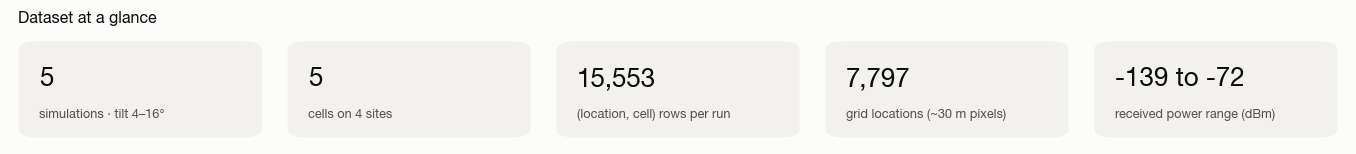

In [6]:
n_sites = site_config[["cell_lat", "cell_lon"]].drop_duplicates().shape[0]
n_locations = raw[SIMS[0]][["ix", "iy"]].drop_duplicates().shape[0]
rx = pd.concat(raw.values())[Y_COLUMN]
stat_tiles(
    [
        (f"{len(SIMS)}", f"simulations · tilt {min(TILT.values())}–{max(TILT.values())}°"),
        (f"{len(CELLS)}", f"cells on {n_sites} sites"),
        (f"{len(raw[SIMS[0]]):,}", "(location, cell) rows per run"),
        (f"{n_locations:,}", "grid locations (~30 m pixels)"),
        (f"{rx.min():.0f} to {rx.max():.0f}", "received power range (dBm)"),
    ],
    title="Dataset at a glance",
)

## 2 · Topology, footprints and ground truth

Each cell is trained as its own GP, on the locations it reaches. The map shows where the sites point and how much the footprints overlap; overlapping areas are where the best-server decision is made, checked in §14. Every cell's footprint is an 800 m disc around its site, shaped by the antenna's horizontal pattern. Network RSRP is the strongest cell's power at each location. Down-tilting pulls energy toward the sites, so coverage at the cell edge collapses as the tilt grows. A twin has to reproduce that trade-off to be useful to a coverage optimiser.

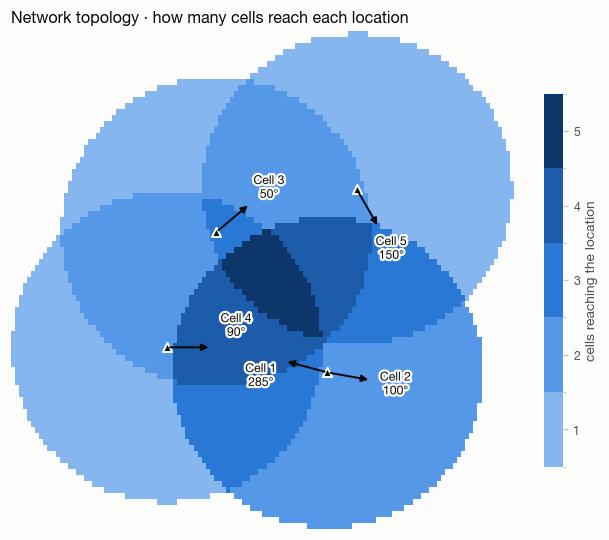

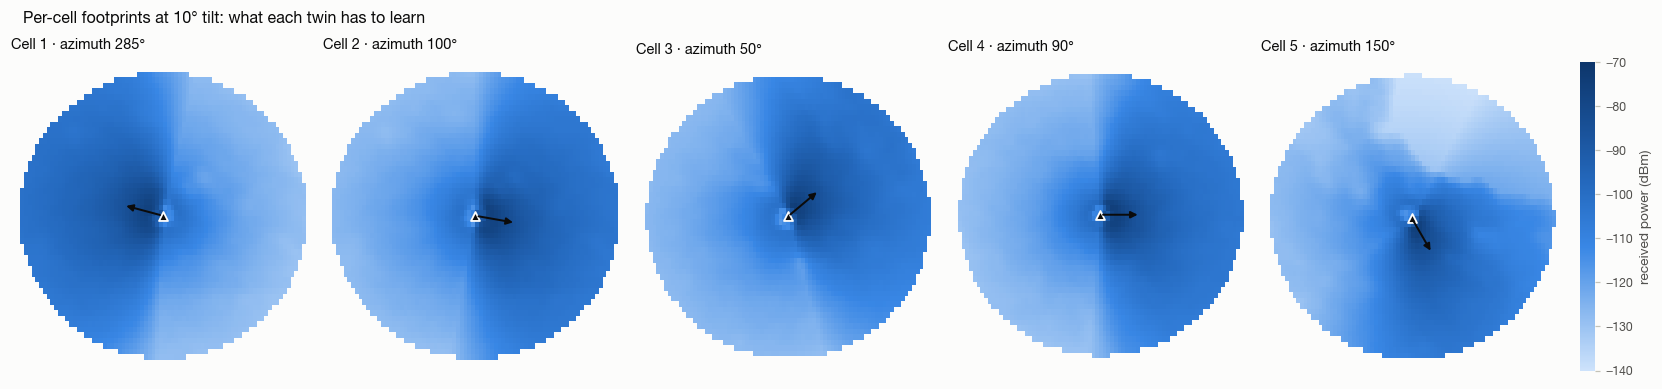

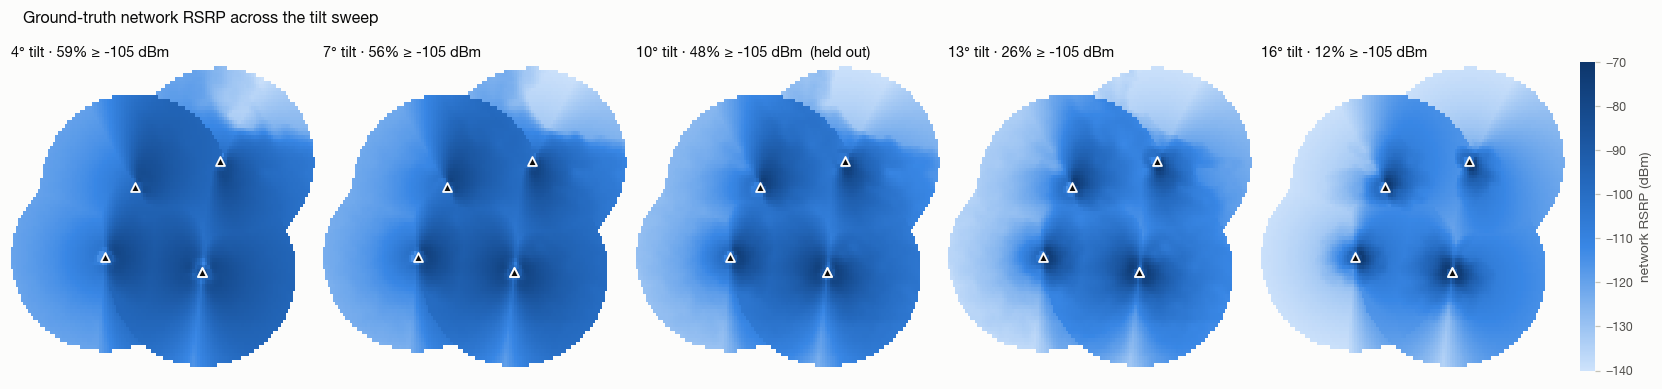

In [7]:
def raster(ix, iy, values):
    grid = np.full((NY, NX), np.nan)
    grid[np.asarray(iy), np.asarray(ix)] = np.asarray(values, dtype=float)
    return grid


LABEL_NUDGE = {1: (0, -14), 4: (0, 14)}  # cells 1 and 4 point at each other; stack their labels


def draw_sites(ax, cells=None, arrows=False, labels=False, arrow_m=230):
    sites = site_config if cells is None else site_config[site_config.cell_id.isin(cells)]
    ax.scatter(sites.cell_lon, sites.cell_lat, marker="^", s=34, color=INK,
               edgecolor=SURFACE, linewidth=1.2, zorder=4)
    if not arrows:
        return
    for cell in sites.itertuples():
        dlat = arrow_m / 111_320 * np.cos(np.deg2rad(cell.cell_az_deg))
        dlon = arrow_m / (111_320 * np.cos(np.deg2rad(cell.cell_lat))) * np.sin(np.deg2rad(cell.cell_az_deg))
        tip = (cell.cell_lon + dlon, cell.cell_lat + dlat)
        ax.annotate("", xy=tip, xytext=(cell.cell_lon, cell.cell_lat),
                    arrowprops=dict(arrowstyle="-|>", color=INK, lw=1.3, mutation_scale=9), zorder=4)
        if labels:
            ax.annotate(f"Cell {cell.cell_id}\n{cell.cell_az_deg}°", tip,
                        xytext=(16 * np.sin(np.deg2rad(cell.cell_az_deg)) + LABEL_NUDGE.get(cell.cell_id, (0, 0))[0],
                                16 * np.cos(np.deg2rad(cell.cell_az_deg)) + LABEL_NUDGE.get(cell.cell_id, (0, 0))[1]),
                        textcoords="offset points", ha="center", va="center",
                        fontsize=8, fontweight="semibold", path_effects=HALO, zorder=5)


def draw_map(ax, ix, iy, values, cmap=RSRP_CMAP, vmin=None, vmax=None, norm=None, title=None, cells=None):
    im = ax.imshow(raster(ix, iy, values), origin="lower", extent=EXTENT, cmap=cmap,
                   vmin=None if norm else vmin, vmax=None if norm else vmax, norm=norm, interpolation="nearest")
    ax.set_aspect(ASPECT)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    draw_sites(ax, cells=cells, arrows=cells is not None)
    if title:
        ax.set_title(title, fontsize=9.5)
    return im


def colorbar(fig, im, ax, label, **kwargs):
    cb = fig.colorbar(im, ax=ax, label=label, **kwargs)
    cb.outline.set_visible(False)
    cb.ax.tick_params(color=AXIS, labelsize=8)
    return cb


def network_view(rows, value_col, extra=()):
    """Strongest cell per grid location: its value and its id (the best server)."""
    best = rows.loc[rows.groupby(["ix", "iy"])[value_col].idxmax()]
    return best[["ix", "iy", "cell_id", value_col, *extra]].reset_index(drop=True)


def zoom_to(ax, rows, pad_px=3):
    """Crop a map to the pixels covered by `rows` (e.g. one cell's footprint)."""
    ax.set_xlim(LON0 + (rows.ix.min() - pad_px) * GRID_STEP, LON0 + (rows.ix.max() + pad_px) * GRID_STEP)
    ax.set_ylim(LAT0 + (rows.iy.min() - pad_px) * GRID_STEP, LAT0 + (rows.iy.max() + pad_px) * GRID_STEP)


overlap = raw[TEST_SIM].groupby(["ix", "iy"]).size().reset_index(name="n_cells")
fig, ax = plt.subplots(figsize=(6.4, 4.8), layout="constrained")
overlap_cmap = ListedColormap(ORDINAL_BLUES)
overlap_cmap.set_bad(SURFACE)
im = draw_map(ax, overlap.ix, overlap.iy, overlap.n_cells, cmap=overlap_cmap,
              norm=BoundaryNorm(np.arange(0.5, 6), overlap_cmap.N))
draw_sites(ax, cells=CELLS, arrows=True, labels=True)
ax.set_title("Network topology · how many cells reach each location")
colorbar(fig, im, ax, "cells reaching the location", ticks=range(1, 6), shrink=0.75)
plt.show()

test_raw = raw[TEST_SIM]
fig, axes = plt.subplots(1, len(CELLS), figsize=(15, 3.6), layout="constrained")
for ax, cell_id in zip(axes, CELLS):
    rows = test_raw[test_raw.cell_id == cell_id]
    im = draw_map(ax, rows.ix, rows.iy, rows[Y_COLUMN], vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
                  title=f"Cell {cell_id} · azimuth {CELL_INFO.loc[cell_id, 'cell_az_deg']}°", cells=[cell_id])
    zoom_to(ax, rows)
colorbar(fig, im, axes, "received power (dBm)", shrink=0.85, pad=0.01)
fig.suptitle(f"Per-cell footprints at {TILT[TEST_SIM]}° tilt: what each twin has to learn",
             x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()

fig, axes = plt.subplots(1, len(SIMS), figsize=(15, 3.6), layout="constrained")
for ax, sim in zip(axes, SIMS):
    net_truth = network_view(raw[sim], Y_COLUMN)
    covered = (net_truth[Y_COLUMN] >= COVERAGE_DBM).mean()
    im = draw_map(ax, net_truth.ix, net_truth.iy, net_truth[Y_COLUMN], vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
                  title=f"{TILT[sim]}° tilt · {covered:.0%} ≥ {COVERAGE_DBM} dBm" + ("  (held out)" if sim == TEST_SIM else ""))
colorbar(fig, im, axes, "network RSRP (dBm)", shrink=0.85, pad=0.01)
fig.suptitle("Ground-truth network RSRP across the tilt sweep", x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()

## 3 · Feature engineering, done by the engine

`SVGPDigitalTwin.preprocess_ue_training_data` takes UE rows (`cell_id`, `lat`, `lon`, the received power and, optionally, the tilt each row was measured at) plus a topology table. It returns one frame per cell with the features added:
- `log_distance` and `relative_bearing`, from the same vectorised `GISTools` helpers the BDT uses
- `antenna_gain`, a vertical antenna-pattern term. It is not used below, so both twins see identical inputs. It is also unclamped: next to a mast it reaches several hundred dB below zero (see the minimum in the table), so clip it before using it as a feature.

Each row **keeps its own tilt**. The topology's `cell_el_deg` only fills rows that have none. That matters here, because every training row comes from a different tilt run.

In [8]:
topology = site_config.drop(columns="nRx")  # its cell_el_deg is only a fallback for rows without a tilt


def engineer_features(df):
    """One simulator run -> the engine's feature frame (all cells stacked)."""
    ue = df.rename(columns={"loc_y": "lat", "loc_x": "lon"})
    return pd.concat(SVGPDigitalTwin.preprocess_ue_training_data(ue, topology), ignore_index=True)


data = {sim: engineer_features(df) for sim, df in raw.items()}
assert all((data[sim].cell_el_deg == TILT[sim]).all() for sim in SIMS), "rows must keep their own tilt"
print("every row kept the tilt of its run ✓")

# parity with the scalar helpers that BayesianDigitalTwin.create_prediction_frames uses
for row in data[TEST_SIM].sample(50, random_state=SEED).itertuples():
    cell = CELL_INFO.loc[row.cell_id]
    assert np.isclose(row.log_distance, GISTools.get_log_distance(cell.cell_lat, cell.cell_lon, row.loc_y, row.loc_x))
    assert np.isclose(row.relative_bearing, GISTools.get_relative_bearing(cell.cell_az_deg, cell.cell_lat, cell.cell_lon, row.loc_y, row.loc_x))
print("engine features match the scalar helpers ✓")
data[TEST_SIM][["cell_id", *X_COLUMNS, "antenna_gain", Y_COLUMN]].describe().round(2)

every row kept the tilt of its run ✓
engine features match the scalar helpers ✓


,cell_id,log_distance,relative_bearing,cell_el_deg,antenna_gain,cell_rxpwr_dbm
count,15553.00,15553.00,15553.00,15553.0,15553.00,15553.00
mean,3.00,6.19,180.10,10.0,-7.53,-112.75
std,1.41,0.50,103.92,0.0,7.61,12.55
min,1.00,1.17,0.00,10.0,-584.87,-139.42
25%,2.00,5.99,90.00,10.0,-8.71,-124.15
50%,3.00,6.34,180.45,10.0,-8.05,-113.77
75%,4.00,6.54,270.00,10.0,-6.67,-102.90
max,5.00,6.69,359.96,10.0,-0.00,-74.54


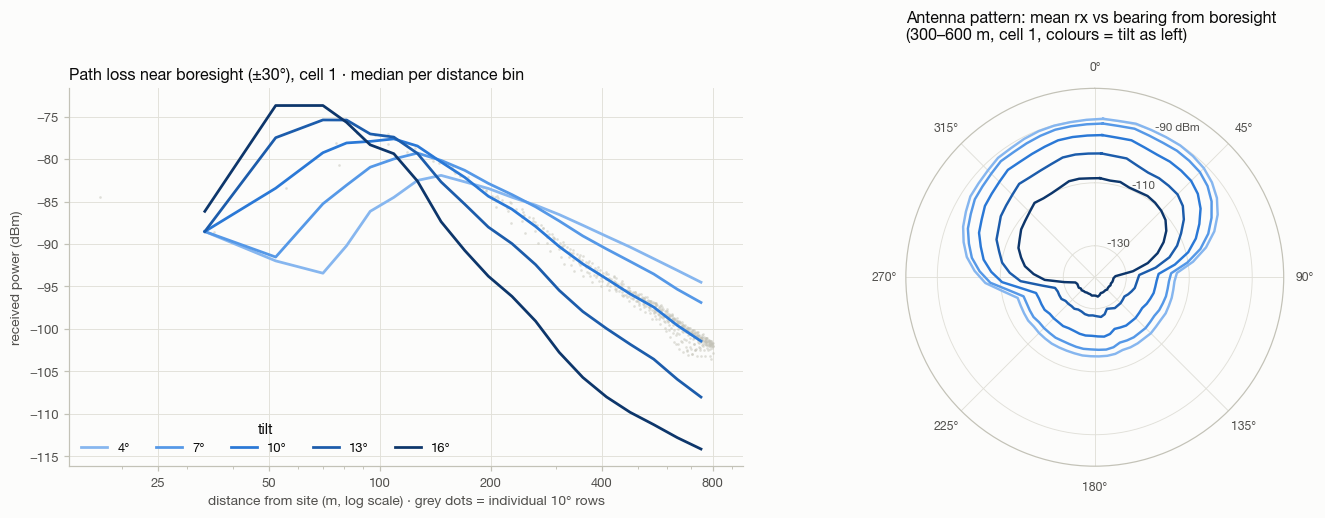

In [9]:
fig = plt.figure(figsize=(13, 4.6), layout="constrained")
ax_pl = fig.add_subplot(1, 2, 1)
ax_ap = fig.add_subplot(1, 2, 2, projection="polar")

dist_bins = np.geomspace(20, 800, 26)
for sim, color in zip(SIMS, ORDINAL_BLUES):
    rows = data[sim][data[sim].cell_id == FOCUS_CELL]
    off_boresight = np.minimum(rows.relative_bearing, 360 - rows.relative_bearing)
    rows = rows[off_boresight <= 30]
    dist_m = np.expm1(rows.log_distance)
    if sim == TEST_SIM:
        ax_pl.scatter(dist_m, rows[Y_COLUMN], s=3, color=AXIS, alpha=0.5, linewidth=0, zorder=1, label="_nolegend_")
    med = rows.groupby(pd.cut(dist_m, dist_bins), observed=True)[Y_COLUMN].median()
    centres = np.sqrt([b.left * b.right for b in med.index])
    ax_pl.plot(centres, med.values, color=color, lw=1.8, label=f"{TILT[sim]}°")
ax_pl.set_xscale("log")
plain_log_axis(ax_pl.xaxis, [25, 50, 100, 200, 400, 800])
ax_pl.set_xlabel("distance from site (m, log scale) · grey dots = individual 10° rows")
ax_pl.set_ylabel("received power (dBm)")
ax_pl.set_title(f"Path loss near boresight (±30°), cell {FOCUS_CELL} · median per distance bin")
ax_pl.legend(title="tilt", ncol=5, loc="lower left")

theta_bins = np.arange(0, 361, 6)
for sim, color in zip(SIMS, ORDINAL_BLUES):
    rows = data[sim][data[sim].cell_id == FOCUS_CELL]
    band = rows[np.expm1(rows.log_distance).between(300, 600)]
    pattern = band.groupby(pd.cut(band.relative_bearing, theta_bins), observed=True)[Y_COLUMN].mean()
    theta = np.deg2rad([b.mid for b in pattern.index])
    ax_ap.plot(np.append(theta, theta[0]), np.append(pattern.values, pattern.values[0]), color=color, lw=1.6)
ax_ap.set_theta_zero_location("N")
ax_ap.set_theta_direction(-1)
ax_ap.set_ylim(-140, -80)
ax_ap.set_yticks([-130, -110, -90])
ax_ap.set_yticklabels(["-130", "-110", "-90 dBm"], fontsize=7.5, color=INK_2)
ax_ap.tick_params(axis="x", labelsize=8)
ax_ap.set_title(f"Antenna pattern: mean rx vs bearing from boresight\n(300–600 m, cell {FOCUS_CELL}, colours = tilt as left)", pad=14)
plt.show()

**What to notice.**
- **Path loss.** Beyond about 150 m, received power falls almost linearly in log distance, which is why the feature is `log_distance` rather than metres.
- **Tilt rotates the curve.** More tilt puts more power close to the mast and less at the cell edge.
- **Antenna pattern.** The front-to-back ratio is roughly 25–30 dB, so a twin has to resolve bearing at a much finer scale than tilt. That is exactly what an under-trained SVGP fails to do (§5).

## 4 · The split, and the exact-GP reference

**Protocol, identical to the BDT notebook.** For every cell, train on a random 20% of that cell's rows from the four runs at **4°, 7°, 13° and 16°**. Evaluate on **every** row of the **10° run**, which no twin ever sees. The tilt is held out; the space is not, because test locations were measured at other tilts.

The exact-GP BDT is trained first on the very same rows, so every SVGP number below has a reference next to it.

In [10]:
train_df = pd.concat(
    [data[sim].groupby("cell_id", group_keys=False).sample(frac=P_TRAIN, random_state=SEED) for sim in TRAIN_SIMS],
    ignore_index=True,
)
test_df = data[TEST_SIM].reset_index(drop=True)
train_frames = [train_df[train_df.cell_id == c].reset_index(drop=True) for c in CELLS]
test_frames = [test_df[test_df.cell_id == c] for c in CELLS]


def bdt_twin(rows, maxiter=100):
    """The exact-GP reference: one BayesianDigitalTwin per cell, trained as in bayesian_digital_twin."""
    twin = BayesianDigitalTwin(data_in=[rows], x_columns=X_COLUMNS, y_columns=[Y_COLUMN])
    start = time.perf_counter()
    twin.train_distributed_gpmodel(maxiter=maxiter)
    return twin, time.perf_counter() - start


def bdt_predict(twin, rows):
    mean, std = twin.predict_distributed_gpmodel([rows.copy()])
    return mean[0], std[0]


bdt, bdt_secs = {}, {}
for cell_id, rows in zip(CELLS, train_frames):
    bdt[cell_id], bdt_secs[cell_id] = bdt_twin(rows)
print(f"BDT reference: {len(CELLS)} cells · {sum(len(f) for f in train_frames):,} rows · {sum(bdt_secs.values()):.1f} s")
pd.DataFrame({"train rows": [len(f) for f in train_frames], "test rows": [len(f) for f in test_frames]},
             index=pd.Index(CELLS, name="cell"))

BDT reference: 5 cells · 12,444 rows · 39.2 s


,train rows,test rows
cell,,
1,2492,3113
2,2492,3113
3,2488,3112
4,2484,3106
5,2488,3109


## 5 · Train the SVGP: count optimiser steps, not epochs

`SVGPTrainConfig` defaults to 100 epochs with mini-batches of 1,024 rows. Those defaults suit large training sets. **One epoch is one pass over a cell's rows**, so the number of optimiser steps is `epochs × ⌈rows / batch_size⌉`. With about 2,500 rows per cell, an epoch is only three steps. The default run then makes 300 small steps, which is not enough to learn a 30° antenna lobe.

Below, the focus cell's twin is trained four times. Each run keeps 100 epochs and shrinks the batch, so the number of steps grows. Each twin is scored on the held-out 10° tilt, next to the BDT trained on the same rows. A single-cell twin trains on its own, the per-cell path; with several cells the engine batches them into one model.

**Early stopping is switched off throughout** (`stopping_threshold=0`). The engine stops when two consecutive epoch losses differ by less than 1e-4. With mini-batches that loss is noisy, so two epochs can match by chance long before training has converged. The first cell below trains this section's configuration with early stopping left on, under four seeds.

In [11]:
def svgp_twin(frames, **overrides):
    """Train an SVGPDigitalTwin on one frame per cell; returns the twin, its loss matrix and wall time.
    Early stopping is off unless a run asks for it: on mini-batch losses it fires at random."""
    twin = SVGPDigitalTwin(device="cpu")
    config = SVGPTrainConfig(**{"seed": SEED, "stopping_threshold": 0.0, **overrides})
    start = time.perf_counter()
    loss = twin.train([f.copy() for f in frames], X_COLUMNS, [Y_COLUMN], config)
    return twin, loss, time.perf_counter() - start


def svgp_predict(twin, frames):
    """Mean and std per frame. Pass one frame per trained cell, in training order; frames may differ in length."""
    means, stds = twin.predict([f.copy() for f in frames])
    return [means[: len(f), i] for i, f in enumerate(frames)], [stds[: len(f), i] for i, f in enumerate(frames)]


def svgp_hyperparameters(twin, i):
    """Learned kernel and noise for cell i in physical units. Reads engine internals: there is no public accessor."""
    if twin._multicell_batched:
        model, likelihood = twin._models[0], twin._likelihoods[0]
        ls = model.covar_module.base_kernel.lengthscale[i]
        outputscale, noise = model.covar_module.outputscale[i], likelihood.noise[i]
    else:
        model, likelihood = twin._models[i], twin._likelihoods[i]
        ls, outputscale, noise = model.covar_module.base_kernel.lengthscale, model.covar_module.outputscale, likelihood.noise
    ls = ls.detach().cpu().numpy().ravel()
    span = (twin._xmax[i] - twin._xmin[i])[X_COLUMNS].values
    y_std = float(twin._ystds[i].iloc[0])
    phys = ls * span
    return {"distance ×": np.exp(phys[0]), "bearing (°)": phys[1], "tilt (°)": phys[2],
            "signal σ (dB)": float(outputscale.detach().sqrt()) * y_std,
            "noise σ (dB)": float(noise.detach().sqrt().ravel()[0]) * y_std}


def bdt_hyperparameters(twin):
    kernel = twin.model.covar_module
    y_std = float(twin.ystds[0].iloc[0])
    phys = kernel.base_kernel.lengthscale.detach().cpu().numpy().ravel() * (twin.xmax[0] - twin.xmin[0])[X_COLUMNS].values
    return {"distance ×": np.exp(phys[0]), "bearing (°)": phys[1], "tilt (°)": phys[2],
            "signal σ (dB)": float(kernel.outputscale.detach().cpu().sqrt()) * y_std,
            "noise σ (dB)": float(twin.model.likelihood.noise.detach().cpu().sqrt()) * y_std}


focus = CELLS.index(FOCUS_CELL)
focus_train, focus_test = train_frames[focus], test_frames[focus]
bdt_focus_mean, bdt_focus_std = bdt_predict(bdt[FOCUS_CELL], focus_test)
bdt_focus = kpis(focus_test[Y_COLUMN], bdt_focus_mean, bdt_focus_std)

# the engine's default early stopping, on the configuration used below, under four seeds
early_stop = []
for seed in range(4):
    twin, loss, secs = svgp_twin([focus_train], batch_size=256, seed=seed, stopping_threshold=1e-4)
    (mean,), _ = svgp_predict(twin, [focus_test])
    trace = loss[0][np.isfinite(loss[0])]
    early_stop.append({"seed": seed, "epochs run (of 100)": len(trace),
                       "last two epoch losses": f"{trace[-2]:.5f} → {trace[-1]:.5f}",
                       "final loss": trace[-1], "MAE (dB)": np.abs(mean - focus_test[Y_COLUMN]).mean()})
pd.DataFrame(early_stop).round(3)

,seed,epochs run (of 100),last two epoch losses,final loss,MAE (dB)
0,0,100,-1.06891 → -1.07228,-1.072,0.835
1,1,84,-1.04922 → -1.04928,-1.049,0.956
2,2,50,-0.73264 → -0.73261,-0.733,1.335
3,3,100,-1.05360 → -1.04989,-1.050,0.992


**What to notice.** Two of the four seeds stopped early. Seed 2 stopped at epoch 50, with a loss of −0.73 where the full runs reach about −1.05, and scored MAE 1.34 dB instead of about 0.84–0.99. The rule fired because two consecutive mini-batch averages happened to agree to within 1e-4, not because training had converged. Every run below disables it.

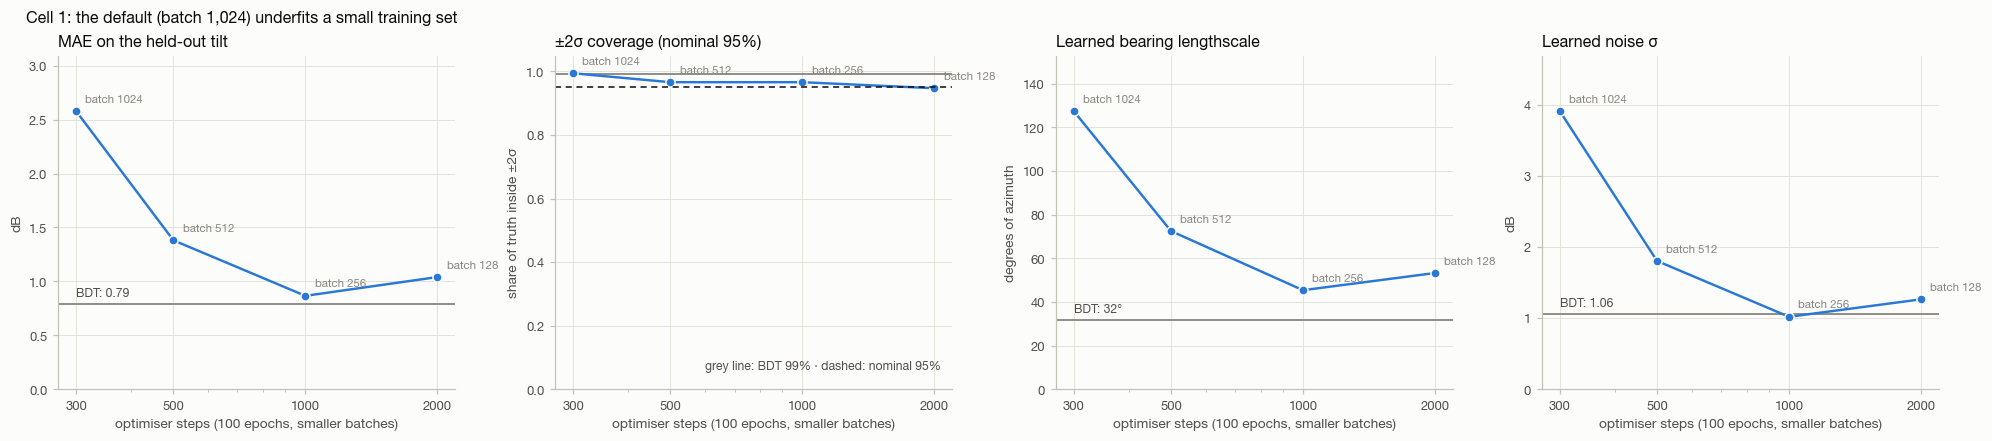

,batch size,epochs,optimiser steps,train s,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,distance ×,bearing (°),tilt (°),signal σ (dB),noise σ (dB)
0,1024,100,300,9.765,2.579,3.169,4.325,6.133,-0.113,0.940,0.789,0.994,5.698,127.466,8.875,11.865,3.914
1,512,100,500,11.141,1.381,1.825,2.459,3.375,-0.348,0.980,0.723,0.966,3.643,72.497,8.942,12.761,1.805
2,256,100,1000,15.028,0.866,1.766,1.449,2.094,-0.384,0.981,0.742,0.966,3.742,45.379,10.749,34.306,1.019
3,128,100,2000,26.262,1.040,1.858,1.704,2.911,-0.225,0.979,0.774,0.947,3.756,53.256,10.235,51.313,1.265


In [12]:
steps_runs = []
for batch_size in [1024, 512, 256, 128]:
    twin, loss, secs = svgp_twin([focus_train], batch_size=batch_size)
    (mean,), (std,) = svgp_predict(twin, [focus_test])
    epochs = int(np.isfinite(loss[0]).sum())
    steps_runs.append({"batch size": batch_size, "epochs": epochs,
                       "optimiser steps": epochs * int(np.ceil(len(focus_train) / batch_size)), "train s": secs,
                       **kpis(focus_test[Y_COLUMN], mean, std), **svgp_hyperparameters(twin, 0)})
steps_runs = pd.DataFrame(steps_runs)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.9), layout="constrained")
for ax, col, title, ref in [
    (axes[0], "MAE (dB)", "MAE on the held-out tilt", bdt_focus["MAE (dB)"]),
    (axes[1], "±2σ coverage", "±2σ coverage (nominal 95%)", bdt_focus["±2σ coverage"]),
    (axes[2], "bearing (°)", "Learned bearing lengthscale", bdt_hyperparameters(bdt[FOCUS_CELL])["bearing (°)"]),
    (axes[3], "noise σ (dB)", "Learned noise σ", bdt_hyperparameters(bdt[FOCUS_CELL])["noise σ (dB)"]),
]:
    ax.axhline(ref, color=MODEL_COLOR["BDT (exact GP)"], lw=1.2)
    if col != "±2σ coverage":  # that panel is crowded near the top; it gets a key at the bottom instead
        label = f"BDT: {ref:.0f}°" if col == "bearing (°)" else f"BDT: {ref:.2f}"
        ax.annotate(label, (steps_runs["optimiser steps"].min(), ref), xytext=(0, 5), textcoords="offset points",
                    fontsize=8, color=INK_2)
    ax.plot(steps_runs["optimiser steps"], steps_runs[col], color=MODEL_COLOR["SVGP"], marker="o", ms=6,
            markeredgecolor=SURFACE)
    for _, r in steps_runs.iterrows():
        ax.annotate(f"batch {r['batch size']:.0f}", (r["optimiser steps"], r[col]), xytext=(6, 6),
                    textcoords="offset points", fontsize=7.5, color=MUTED)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, steps_runs["optimiser steps"].tolist())
    ax.set_xlabel("optimiser steps (100 epochs, smaller batches)")
    ax.set_title(title)
    ax.set_ylim(0, max(steps_runs[col].max(), ref) * 1.2)
axes[1].axhline(0.95, color=INK, lw=1, ls=(0, (4, 3)))
axes[1].set_ylim(0, 1.05)
axes[1].text(0.97, 0.06, f"grey line: BDT {bdt_focus['±2σ coverage']:.0%} · dashed: nominal 95%",
             transform=axes[1].transAxes, ha="right", fontsize=8, color=INK_2)
axes[0].set_ylabel("dB")
axes[1].set_ylabel("share of truth inside ±2σ")
axes[2].set_ylabel("degrees of azimuth")
axes[3].set_ylabel("dB")
fig.suptitle(f"Cell {FOCUS_CELL}: the default (batch 1,024) underfits a small training set",
             x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()
steps_runs.round(3)

**What to notice.**
- **The default underfits.** At 300 steps (batch 1,024) MAE is 2.6 dB. The bearing lengthscale is about 127° where the BDT learns 32°, and the twin explains the unresolved antenna lobe as about 4 dB of noise.
- **About 1,000 steps closes most of the gap.** Batch 256 gives MAE about 0.87 dB and a 45° lengthscale. 2,000 steps adds nothing.
- **±2σ coverage stays near nominal throughout.** An underfitted SVGP is wide, not overconfident.

SVGP: 5 cells in one batched model · 500 inducing points per cell · batch 256 · 77.2 s


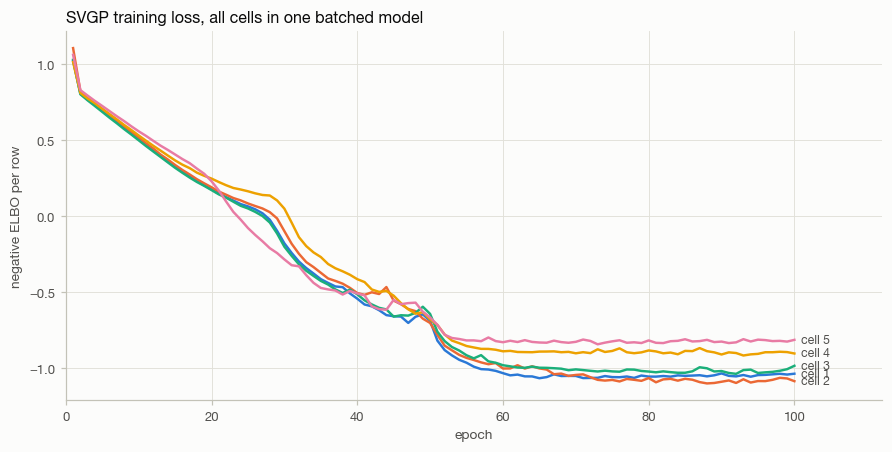

In [13]:
SVGP_KW = {"batch_size": 256}  # ~1,000 optimiser steps on ~2,500 rows per cell; early stopping off, the rest default

svgp, svgp_loss, svgp_secs = svgp_twin(train_frames, **SVGP_KW)
print(f"SVGP: {len(CELLS)} cells in one batched model · {SVGPTrainConfig().num_inducing} inducing points per cell · "
      f"batch {SVGP_KW['batch_size']} · {svgp_secs:.1f} s")

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for i, cell_id in enumerate(CELLS):
    loss = svgp_loss[i][np.isfinite(svgp_loss[i])]
    ax.plot(np.arange(1, len(loss) + 1), loss, color=CELL_COLOR[cell_id])
    ax.annotate(f"cell {cell_id}", (len(loss), loss[-1]), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=INK_2)
ax.set_xlabel("epoch")
ax.set_ylabel("negative ELBO per row")
ax.set_xlim(0, len(svgp_loss[0]) * 1.12)
ax.set_title("SVGP training loss, all cells in one batched model")
plt.show()

### Watch it learn

The focus cell's twin predicting the held-out 10° footprint after 1, 5, 20 and 100 epochs of the §5 configuration. The top row is the prediction and the bottom row its error. `train` always starts from scratch, so each panel is a fresh twin trained for that many epochs. The inducing points freeze halfway through each run, so the panels are not snapshots of one run.

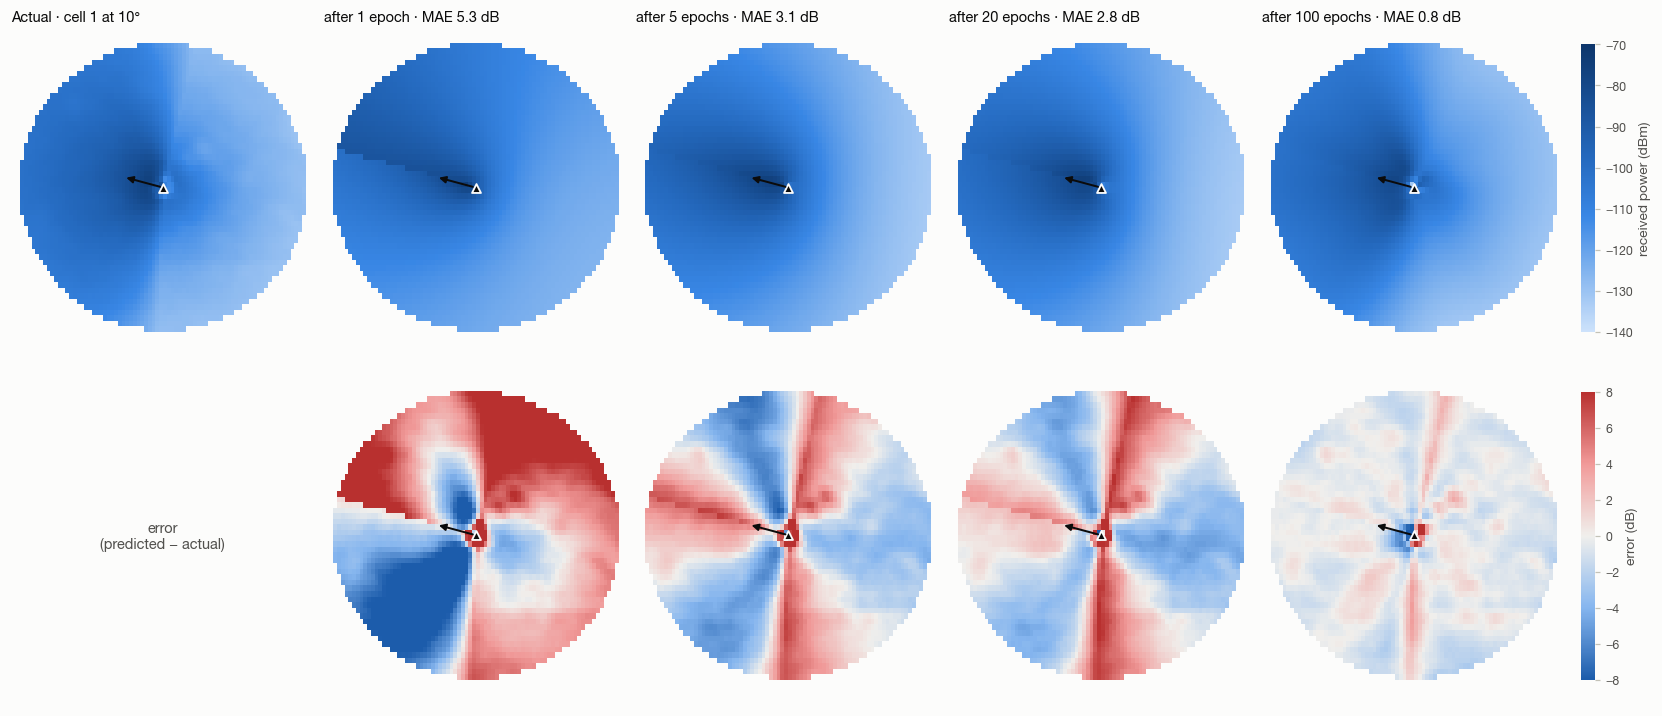

In [14]:
epochs_shown = [1, 5, 20, 100]
fig, axes = plt.subplots(2, len(epochs_shown) + 1, figsize=(15, 6.4), layout="constrained")
draw_map(axes[0, 0], focus_test.ix, focus_test.iy, focus_test[Y_COLUMN], vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
         title=f"Actual · cell {FOCUS_CELL} at {TILT[TEST_SIM]}°", cells=[FOCUS_CELL])
zoom_to(axes[0, 0], focus_test)
axes[1, 0].set_axis_off()
axes[1, 0].text(0.5, 0.5, "error\n(predicted − actual)", ha="center", va="center", color=INK_2, fontsize=9.5,
                transform=axes[1, 0].transAxes)
for col, epochs in enumerate(epochs_shown, start=1):
    twin, _, _ = svgp_twin([focus_train], num_epochs=epochs, **SVGP_KW)
    (mean,), _ = svgp_predict(twin, [focus_test])
    err = mean - focus_test[Y_COLUMN].values
    im_rx = draw_map(axes[0, col], focus_test.ix, focus_test.iy, mean, vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1],
                     title=f"after {epochs} epoch{'s' if epochs > 1 else ''} · MAE {np.abs(err).mean():.1f} dB", cells=[FOCUS_CELL])
    im_err = draw_map(axes[1, col], focus_test.ix, focus_test.iy, err, cmap=ERROR_CMAP,
                      norm=TwoSlopeNorm(0, -8, 8), cells=[FOCUS_CELL])
    for ax in axes[:, col]:
        zoom_to(ax, focus_test)
colorbar(fig, im_rx, axes[0, :], "received power (dBm)", shrink=0.85, pad=0.01)
colorbar(fig, im_err, axes[1, :], "error (dB)", shrink=0.85, pad=0.01)
plt.show()

## 6 · What the twin learned

The same ARD reading as the BDT notebook: each lengthscale, converted back to physical units, says how far you move along that feature before the power decorrelates. The SVGP and the exact GP see identical rows, so their lengthscales should agree if both fitted the data.

The second figure shows where the focus cell's inducing points ended up. They are the M locations in feature space that summarise the whole cell, so they should spread over the footprint and crowd where the field changes fastest.

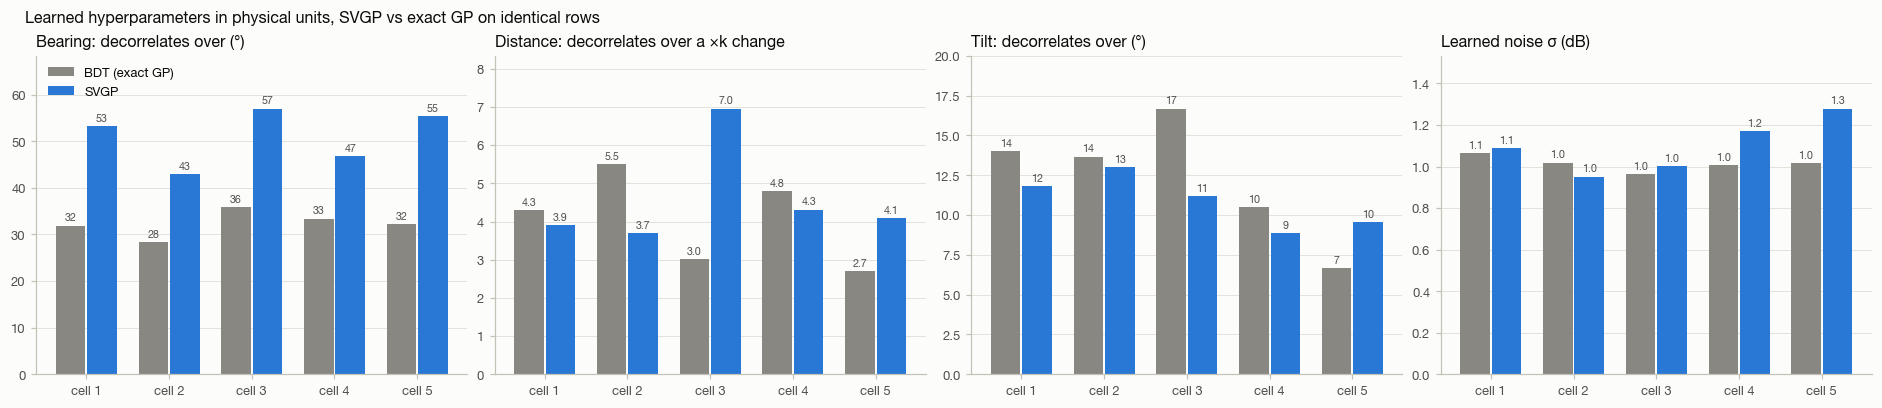

distance ×  bearing (°)  tilt (°)  signal σ (dB)  \
model          cell                                                     
BDT (exact GP) 1          4.301       31.927    14.030         17.042   
               2          5.497       28.340    13.665         15.044   
               3          3.025       35.912    16.677         16.640   
               4          4.795       33.416    10.498         16.049   
               5          2.703       32.155     6.651         12.513   
SVGP           1          3.898       53.250    11.826         31.612   
               2          3.701       43.033    13.019         37.129   
               3          6.955       57.000    11.208         28.006   
               4          4.314       46.785     8.857         30.588   
               5          4.092       55.435     9.556         32.409   

                     noise σ (dB)  
model          cell                
BDT (exact GP) 1            1.063  
               2            1.019  
               3            0.964  
               4            1.008  
               5            1.018  
SVGP           1            1.090  
               2            0.952  
               3            1.002  
               4            1.171  
               5            1.279

In [15]:
hp = pd.concat(
    {
        "BDT (exact GP)": pd.DataFrame({c: bdt_hyperparameters(bdt[c]) for c in CELLS}).T,
        "SVGP": pd.DataFrame({c: svgp_hyperparameters(svgp, i) for i, c in enumerate(CELLS)}).T,
    },
    names=["model", "cell"],
)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), layout="constrained")
width = 0.38
for ax, (col, title, fmt) in zip(axes, [
    ("bearing (°)", "Bearing: decorrelates over (°)", "{:.0f}"),
    ("distance ×", "Distance: decorrelates over a ×k change", "{:.1f}"),
    ("tilt (°)", "Tilt: decorrelates over (°)", "{:.0f}"),
    ("noise σ (dB)", "Learned noise σ (dB)", "{:.1f}"),
]):
    for k, model in enumerate(MODEL_COLOR):
        values = hp.loc[model, col]
        bars = ax.bar(np.arange(len(CELLS)) + (k - 0.5) * width, values, width=width * 0.94,
                      color=MODEL_COLOR[model], label=model)
        ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=2, fontsize=7, color=INK_2)
    ax.set_xticks(np.arange(len(CELLS)))
    ax.set_xticklabels([f"cell {c}" for c in CELLS])
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, hp[col].max() * 1.2)
axes[0].legend(loc="upper left")
fig.suptitle("Learned hyperparameters in physical units, SVGP vs exact GP on identical rows",
             x=0.01, ha="left", fontsize=10.5, fontweight="semibold")
plt.show()
hp.round(3)

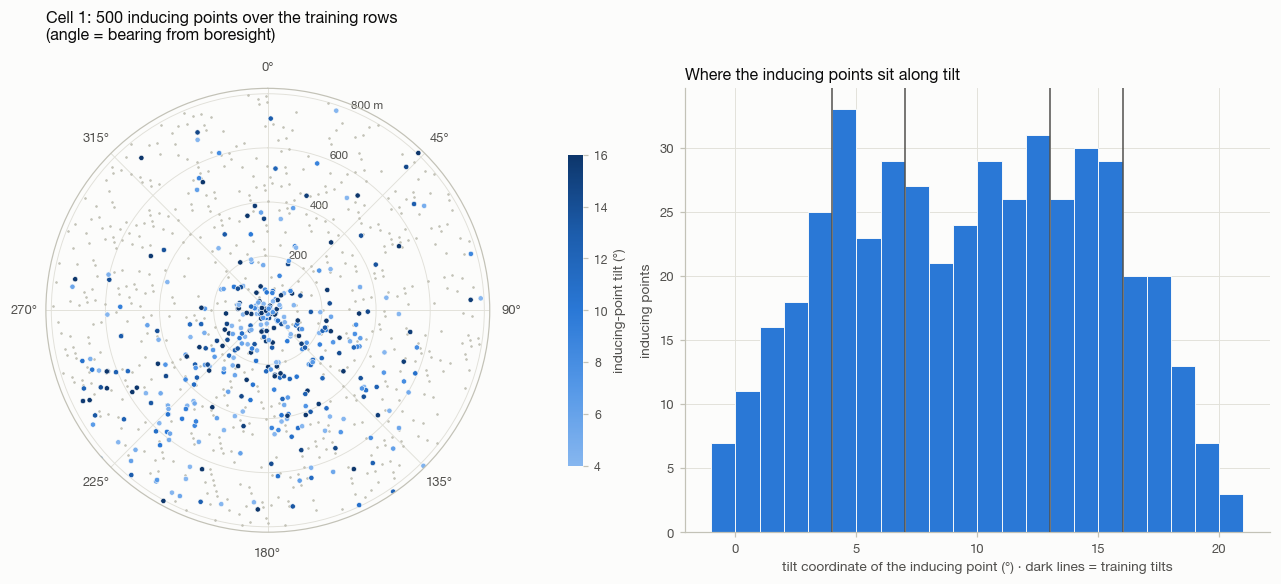

In [16]:
inducing = svgp._models[0].variational_strategy.inducing_points[focus].detach().cpu().numpy()
span = (svgp._xmax[focus] - svgp._xmin[focus])[X_COLUMNS].values
inducing = inducing * span + svgp._xmin[focus][X_COLUMNS].values  # back to physical units

fig = plt.figure(figsize=(12.5, 5.2), layout="constrained")
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax.scatter(np.deg2rad(focus_train.relative_bearing), np.expm1(focus_train.log_distance), s=2, color=AXIS,
           alpha=0.6, linewidth=0, label="training rows")
tilt_cmap = LinearSegmentedColormap.from_list("tilt", ORDINAL_BLUES)
sc = ax.scatter(np.deg2rad(inducing[:, 1]), np.expm1(inducing[:, 0]), s=12, c=inducing[:, 2], cmap=tilt_cmap,
                vmin=min(TILT.values()), vmax=max(TILT.values()), edgecolor=SURFACE, linewidth=0.4,
                label="inducing points")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_rlim(0, 820)
ax.set_rticks([200, 400, 600, 800])
ax.set_yticklabels(["200", "400", "600", "800 m"], fontsize=7.5, color=INK_2)
ax.set_title(f"Cell {FOCUS_CELL}: {len(inducing)} inducing points over the training rows\n(angle = bearing from boresight)", pad=14)
colorbar(fig, sc, ax, "inducing-point tilt (°)", shrink=0.7, pad=0.08)

ax = fig.add_subplot(1, 2, 2)
ax.hist(inducing[:, 2], bins=np.arange(-1, 22, 1), color=MODEL_COLOR["SVGP"], edgecolor=SURFACE, linewidth=0.6)
for tilt in sorted({TILT[s] for s in TRAIN_SIMS}):
    ax.axvline(tilt, color=INK_2, lw=1, zorder=3)
ax.set_xlabel("tilt coordinate of the inducing point (°) · dark lines = training tilts")
ax.set_ylabel("inducing points")
ax.set_title("Where the inducing points sit along tilt")
plt.show()

**What to notice.**
- **The SVGP is smoother in bearing:** 43–57° against the BDT's 28–36°. That is the main reason it is slightly less accurate on identical rows.
- **Tilt and noise agree with the exact GP:** 9–13° in tilt, noise σ about 1 dB. Distance is similar except cell 3.
- **The inducing points cover the footprint** and crowd near the mast, where the field changes fastest. Along tilt they spread across and slightly beyond the training tilts.

## 7 · Accuracy on the held-out tilt

The batched model predicts every cell in one call: `predict` takes one frame per cell, in training order, and returns `[rows, cells]` arrays. Two views are scored, as in the BDT notebook:
- **Per-cell rows.** Every (location, cell) prediction against its truth.
- **Network RSRP.** The strongest predicted cell per location against the strongest true cell, which is what a CCO or MRO application consumes.

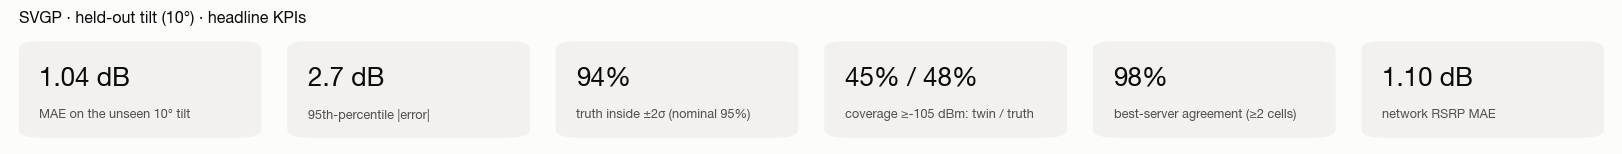

,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,rows
cell 1,0.950,1.418,1.732,2.472,-0.404,0.988,0.693,0.942,3113
cell 2,0.822,1.230,1.333,2.001,-0.362,0.990,0.720,0.963,3113
cell 3,0.871,1.690,1.457,2.072,-0.367,0.978,0.709,0.956,3112
cell 4,1.151,1.485,2.048,2.634,-0.834,0.985,0.609,0.947,3106
cell 5,1.416,2.068,2.442,3.422,-0.528,0.975,0.593,0.882,3109
all cells (per-cell rows),1.042,1.604,1.814,2.679,-0.499,0.984,0.665,0.938,15553
network RSRP (strongest cell),1.103,1.639,1.973,2.980,-0.518,0.986,NaN,NaN,7797


In [17]:
def predict_all(df):
    """SVGP posterior for every (location, cell) row of a simulation, joined back onto the frame."""
    frames = [df[df.cell_id == c] for c in CELLS]
    means, stds = svgp_predict(svgp, frames)
    parts = [pd.DataFrame({"pred_dbm": m, "pred_std_db": s}, index=f.index) for f, m, s in zip(frames, means, stds)]
    return df.join(pd.concat(parts))


def network_compare(df):
    """Join true and predicted network views (RSRP + best server) on grid location."""
    truth = network_view(df, Y_COLUMN).rename(columns={"cell_id": "true_server", Y_COLUMN: "true_rsrp"})
    pred = network_view(df, "pred_dbm", extra=["pred_std_db"]).rename(
        columns={"cell_id": "pred_server", "pred_dbm": "pred_rsrp", "pred_std_db": "pred_rsrp_std"}
    )
    n_cells = df.groupby(["ix", "iy"]).size().rename("n_cells").reset_index()
    return truth.merge(pred, on=["ix", "iy"]).merge(n_cells, on=["ix", "iy"])


start = time.perf_counter()
test_df = predict_all(test_df)
svgp_first_secs = time.perf_counter() - start  # the first call, timed again warm in §10
net = network_compare(test_df)

rows = {f"cell {c}": kpis(g[Y_COLUMN], g.pred_dbm, g.pred_std_db) for c, g in test_df.groupby("cell_id")}
rows["all cells (per-cell rows)"] = kpis(test_df[Y_COLUMN], test_df.pred_dbm, test_df.pred_std_db)
rows["network RSRP (strongest cell)"] = kpis(net.true_rsrp, net.pred_rsrp)
kpi_table = pd.DataFrame(rows).T
kpi_table["rows"] = [*test_df.groupby("cell_id").size().tolist(), len(test_df), len(net)]

overall = kpi_table.loc["all cells (per-cell rows)"]
true_cov, pred_cov = (net.true_rsrp >= COVERAGE_DBM).mean(), (net.pred_rsrp >= COVERAGE_DBM).mean()
multi = net[net.n_cells >= 2]
server_agreement = (multi.true_server == multi.pred_server).mean()
stat_tiles(
    [
        (f"{overall['MAE (dB)']:.2f} dB", "MAE on the unseen 10° tilt"),
        (f"{overall['P95 |err| (dB)']:.1f} dB", "95th-percentile |error|"),
        (f"{overall['±2σ coverage']:.0%}", "truth inside ±2σ (nominal 95%)"),
        (f"{pred_cov:.0%} / {true_cov:.0%}", f"coverage ≥{COVERAGE_DBM} dBm: twin / truth"),
        (f"{server_agreement:.0%}", "best-server agreement (≥2 cells)"),
        (f"{kpi_table.loc['network RSRP (strongest cell)', 'MAE (dB)']:.2f} dB", "network RSRP MAE"),
    ],
    title=f"SVGP · held-out tilt ({TILT[TEST_SIM]}°) · headline KPIs",
)
kpi_table.round(3)

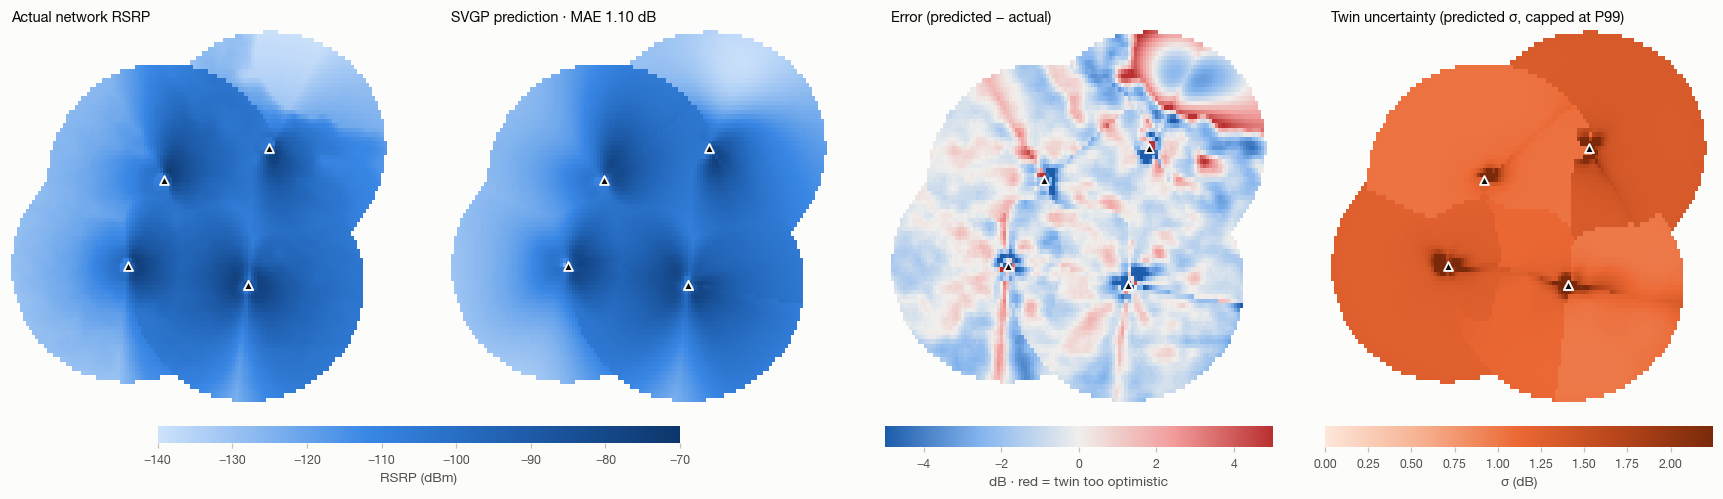

In [18]:
err = net.pred_rsrp - net.true_rsrp
err_lim = np.ceil(np.percentile(np.abs(err), 99))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4), layout="constrained")
for ax, values, title in [
    (axes[0], net.true_rsrp, "Actual network RSRP"),
    (axes[1], net.pred_rsrp, f"SVGP prediction · MAE {np.abs(err).mean():.2f} dB"),
]:
    im = draw_map(ax, net.ix, net.iy, values, vmin=RSRP_RANGE[0], vmax=RSRP_RANGE[1], title=title)
colorbar(fig, im, axes[:2], "RSRP (dBm)", location="bottom", shrink=0.6, aspect=30)
im = draw_map(axes[2], net.ix, net.iy, err, cmap=ERROR_CMAP, norm=TwoSlopeNorm(0, -err_lim, err_lim),
              title="Error (predicted − actual)")
colorbar(fig, im, axes[2], "dB · red = twin too optimistic", location="bottom", shrink=0.9, aspect=18)
im = draw_map(axes[3], net.ix, net.iy, net.pred_rsrp_std, cmap=SIGMA_CMAP, vmin=0,
              vmax=np.percentile(net.pred_rsrp_std, 99), title="Twin uncertainty (predicted σ, capped at P99)")
colorbar(fig, im, axes[3], "σ (dB)", location="bottom", shrink=0.9, aspect=18)
plt.show()

**What to notice.** MAE is about 1.0 dB on the unseen tilt, against 0.88 dB for the BDT on the same rows (§10). The error maps show the same two patterns as the BDT: speckle around the masts, and an optimistic band along the footprint edges.

## 8 · Error diagnostics

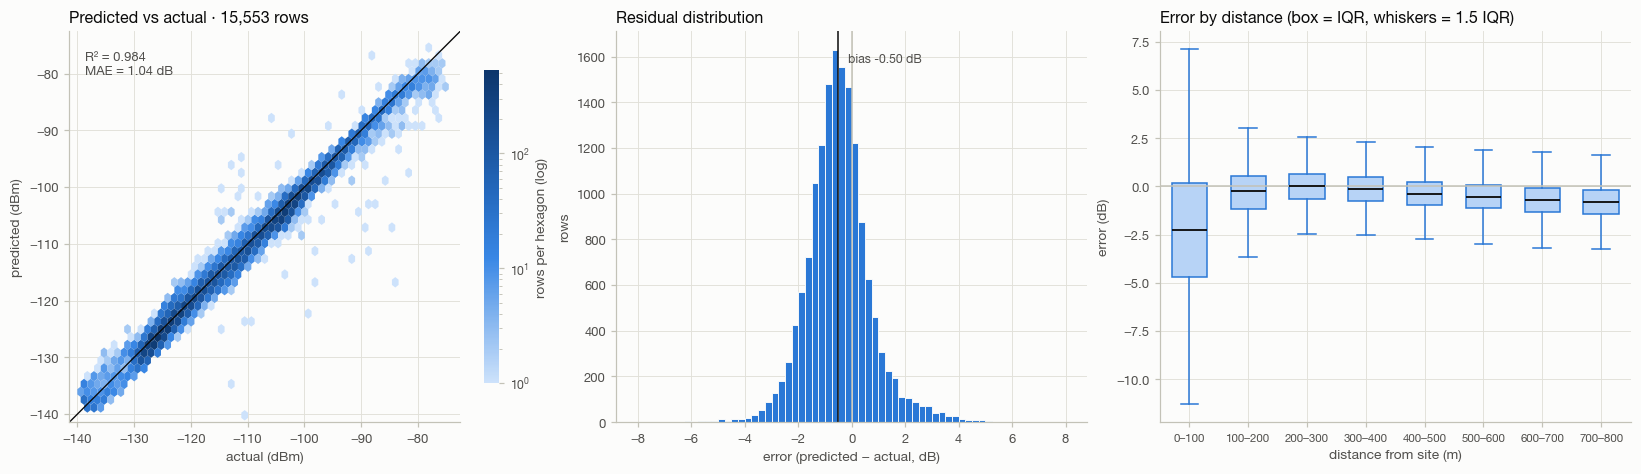

In [19]:
err_rows = test_df.pred_dbm - test_df[Y_COLUMN]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), layout="constrained")

ax = axes[0]
hb = ax.hexbin(test_df[Y_COLUMN], test_df.pred_dbm, gridsize=55, bins="log", mincnt=1, cmap=RSRP_CMAP, linewidths=0)
lims = [test_df[Y_COLUMN].min() - 2, test_df[Y_COLUMN].max() + 2]
ax.plot(lims, lims, color=INK, lw=0.9)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_aspect("equal")
ax.set_xlabel("actual (dBm)")
ax.set_ylabel("predicted (dBm)")
ax.set_title(f"Predicted vs actual · {len(test_df):,} rows")
ax.text(0.04, 0.95, f"R² = {overall['R²']:.3f}\nMAE = {overall['MAE (dB)']:.2f} dB", transform=ax.transAxes,
        va="top", fontsize=8.5, color=INK_2)
colorbar(fig, hb, ax, "rows per hexagon (log)", shrink=0.8)

ax = axes[1]
ax.hist(err_rows, bins=np.arange(-8, 8.01, 0.25), color=SLOTS[0], edgecolor=SURFACE, linewidth=0.6)
ax.axvline(0, color=AXIS, lw=1)
ax.axvline(err_rows.mean(), color=INK, lw=1)
ax.annotate(f"bias {err_rows.mean():+.2f} dB", (err_rows.mean(), ax.get_ylim()[1] * 0.92), xytext=(6, 0),
            textcoords="offset points", fontsize=8, color=INK_2)
ax.set_xlabel("error (predicted − actual, dB)")
ax.set_ylabel("rows")
ax.set_title("Residual distribution")

ax = axes[2]
edges = np.arange(0, 801, 100)
dist_m = np.expm1(test_df.log_distance)
groups = [err_rows[(dist_m >= lo) & (dist_m < hi)].values for lo, hi in zip(edges[:-1], edges[1:])]
ax.boxplot(groups, positions=np.arange(len(groups)), widths=0.6, showfliers=False, patch_artist=True,
           medianprops=dict(color=INK, lw=1.2), whiskerprops=dict(color=SLOTS[0]), capprops=dict(color=SLOTS[0]),
           boxprops=dict(facecolor="#b7d3f6", edgecolor=SLOTS[0]))
ax.axhline(0, color=AXIS, lw=1)
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels([f"{lo}–{hi}" for lo, hi in zip(edges[:-1], edges[1:])], rotation=0, fontsize=7.5)
ax.set_xlabel("distance from site (m)")
ax.set_ylabel("error (dB)")
ax.set_title("Error by distance (box = IQR, whiskers = 1.5 IQR)")
plt.show()

**What to notice.** Predictions hug the diagonal (R² 0.984). The residuals are centred slightly below zero (bias about −0.5 dB). The largest errors sit within 100 m of the masts; beyond that, the middle half of the errors stays within about ±1.5 dB.

## 9 · Is the uncertainty honest? (calibration)

For a calibrated twin the truth falls inside ±kσ with the Gaussian probability: 68% for k = 1 and 95% for k = 2. The reliability diagram draws both twins on the same held-out rows.

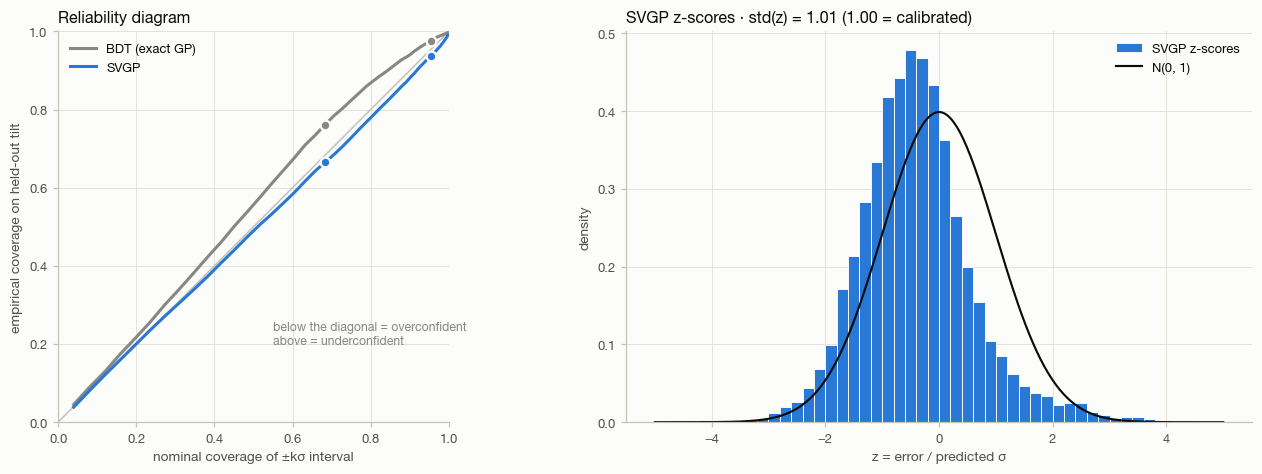

{'BDT (exact GP)': '±1σ 76% · ±2σ 98% · std(z) 0.76', 'SVGP': '±1σ 66% · ±2σ 94% · std(z) 1.01'}


In [20]:
test_df["bdt_dbm"], test_df["bdt_std_db"] = np.nan, np.nan
start = time.perf_counter()
for cell_id, rows in test_df.groupby("cell_id"):
    mean, std = bdt_predict(bdt[cell_id], rows[X_COLUMNS + ["cell_id"]])
    test_df.loc[rows.index, "bdt_dbm"], test_df.loc[rows.index, "bdt_std_db"] = mean, std
bdt_first_secs = time.perf_counter() - start  # the BDT's first call also builds its posterior cache

k = np.linspace(0.05, 3, 60)
nominal = 2 * stats.norm.cdf(k) - 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
ax = axes[0]
ax.plot([0, 1], [0, 1], color=AXIS, lw=1)
z_by_model = {
    "BDT (exact GP)": ((test_df.bdt_dbm - test_df[Y_COLUMN]) / test_df.bdt_std_db).values,
    "SVGP": ((test_df.pred_dbm - test_df[Y_COLUMN]) / test_df.pred_std_db).values,
}
for model, z in z_by_model.items():
    ax.plot(nominal, [(np.abs(z) <= kk).mean() for kk in k], color=MODEL_COLOR[model], lw=2, label=model)
    for kk in (1, 2):
        nom, emp = 2 * stats.norm.cdf(kk) - 1, (np.abs(z) <= kk).mean()
        ax.scatter([nom], [emp], s=40, color=MODEL_COLOR[model], edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.text(0.55, 0.2, "below the diagonal = overconfident\nabove = underconfident", fontsize=8, color=MUTED)
ax.set_xlabel("nominal coverage of ±kσ interval")
ax.set_ylabel("empirical coverage on held-out tilt")
ax.set_title("Reliability diagram")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.legend(loc="upper left")

ax = axes[1]
z = z_by_model["SVGP"]
ax.hist(z, bins=np.arange(-5, 5.01, 0.2), density=True, color=MODEL_COLOR["SVGP"], edgecolor=SURFACE,
        linewidth=0.6, label="SVGP z-scores")
grid = np.linspace(-5, 5, 300)
ax.plot(grid, stats.norm.pdf(grid), color=INK, lw=1.4, label="N(0, 1)")
ax.set_xlabel("z = error / predicted σ")
ax.set_ylabel("density")
ax.set_title(f"SVGP z-scores · std(z) = {z.std():.2f} (1.00 = calibrated)")
ax.legend(loc="upper right")
plt.show()
print({m: f"±1σ {(np.abs(z) <= 1).mean():.0%} · ±2σ {(np.abs(z) <= 2).mean():.0%} · std(z) {z.std():.2f}"
       for m, z in z_by_model.items()})

**What to notice.** The SVGP is the better-calibrated twin on the held-out tilt. ±1σ / ±2σ cover 66% / 94% against nominal 68% / 95%, with std(z) about 1.0. The BDT is underconfident: 76% / 98%, std(z) about 0.76.

## 10 · SVGP vs exact GP, head to head

Same rows in, same held-out tilt out. Cost is part of the comparison: training time for all five cells, inference latency and the size of the saved model. Latency is timed twice. The first call after training includes the BDT building its posterior cache; later calls reuse it. The BDT saves through `save_model_map_to_pickle`; the SVGP saves a `torch.save` checkpoint through `SVGPDigitalTwin.save`.

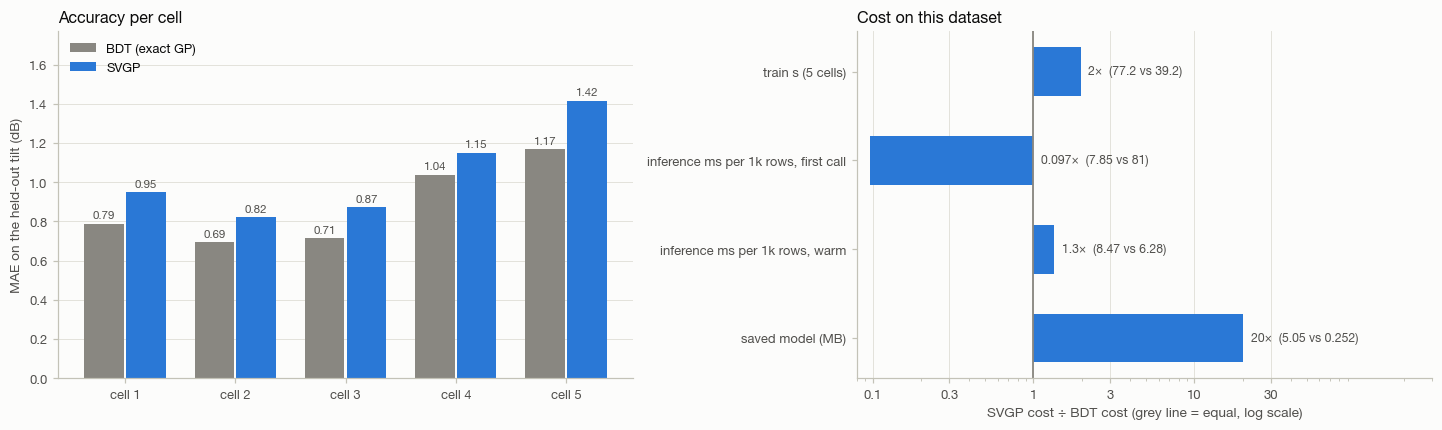

,BDT (exact GP),SVGP
MAE (dB),0.881,1.042
RMSE (dB),1.371,1.604
P85 |err| (dB),1.470,1.814
P95 |err| (dB),2.130,2.679
bias (dB),-0.496,-0.499
R²,0.988,0.984
±1σ coverage,0.761,0.665
±2σ coverage,0.976,0.938
train s (5 cells),39.173,77.170
"inference ms per 1k rows, first call",81.035,7.850


In [21]:
start = time.perf_counter()
for cell_id, rows in test_df.groupby("cell_id"):
    bdt_predict(bdt[cell_id], rows[X_COLUMNS + ["cell_id"]])
bdt_warm_secs = time.perf_counter() - start
start = time.perf_counter()
predict_all(test_df[["cell_id", *X_COLUMNS]])
svgp_warm_secs = time.perf_counter() - start

with tempfile.TemporaryDirectory() as tmp:
    BayesianDigitalTwin.save_model_map_to_pickle(f"{tmp}/bdt.pickle", bdt)
    svgp.save(f"{tmp}/svgp.pt")
    size_mb = {"BDT (exact GP)": Path(f"{tmp}/bdt.pickle").stat().st_size / 1e6,
               "SVGP": Path(f"{tmp}/svgp.pt").stat().st_size / 1e6}

compare = pd.DataFrame(
    {
        "BDT (exact GP)": {**kpis(test_df[Y_COLUMN], test_df.bdt_dbm, test_df.bdt_std_db),
                           "train s (5 cells)": sum(bdt_secs.values()),
                           "inference ms per 1k rows, first call": 1e6 * bdt_first_secs / len(test_df),
                           "inference ms per 1k rows, warm": 1e6 * bdt_warm_secs / len(test_df),
                           "saved model (MB)": size_mb["BDT (exact GP)"]},
        "SVGP": {**kpis(test_df[Y_COLUMN], test_df.pred_dbm, test_df.pred_std_db),
                 "train s (5 cells)": svgp_secs,
                 "inference ms per 1k rows, first call": 1e6 * svgp_first_secs / len(test_df),
                 "inference ms per 1k rows, warm": 1e6 * svgp_warm_secs / len(test_df),
                 "saved model (MB)": size_mb["SVGP"]},
    }
)

per_cell = pd.DataFrame(
    {model: (test_df[col] - test_df[Y_COLUMN]).abs().groupby(test_df.cell_id).mean()
     for model, col in [("BDT (exact GP)", "bdt_dbm"), ("SVGP", "pred_dbm")]}
)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
ax = axes[0]
width = 0.38
for k, model in enumerate(MODEL_COLOR):
    bars = ax.bar(np.arange(len(CELLS)) + (k - 0.5) * width, per_cell[model], width=width * 0.94,
                  color=MODEL_COLOR[model], label=model)
    ax.bar_label(bars, labels=[f"{v:.2f}" for v in per_cell[model]], padding=2, fontsize=7.5, color=INK_2)
ax.set_xticks(np.arange(len(CELLS)))
ax.set_xticklabels([f"cell {c}" for c in CELLS])
ax.set_ylabel("MAE on the held-out tilt (dB)")
ax.set_title("Accuracy per cell")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, per_cell.values.max() * 1.25)
ax.legend(loc="upper left")

ax = axes[1]
metrics = ["train s (5 cells)", "inference ms per 1k rows, first call", "inference ms per 1k rows, warm", "saved model (MB)"]
ratios = np.array([compare.loc[m, "SVGP"] / compare.loc[m, "BDT (exact GP)"] for m in metrics])
# bars grow from the parity line: right = the SVGP costs more, left = it costs less
bars = ax.barh(metrics, ratios - 1, left=1, color=MODEL_COLOR["SVGP"], height=0.55)
ax.axvline(1, color=MODEL_COLOR["BDT (exact GP)"], lw=1.2)
for y, (m, r) in enumerate(zip(metrics, ratios)):
    ax.annotate(f"{r:.2g}×  ({compare.loc[m, 'SVGP']:.3g} vs {compare.loc[m, 'BDT (exact GP)']:.3g})",
                (max(r, 1), y), xytext=(5, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
ax.invert_yaxis()
ax.set_xscale("log")
plain_log_axis(ax.xaxis, [0.1, 0.3, 1, 3, 10, 30])
ax.set_xlim(0.08, 300)
ax.set_xlabel("SVGP cost ÷ BDT cost (grey line = equal, log scale)")
ax.set_title("Cost on this dataset")
ax.grid(axis="y", visible=False)
plt.show()
compare.round(3)

**What to notice.**
- **Accuracy:** the SVGP is about 0.15 dB worse on average.
- **Training:** on about 2,500 rows per cell it is roughly 2× *slower* than the exact GP. The SVGP pays off at larger sizes (§11).
- **Inference:** the first call is about 10× faster than the BDT's, which builds its posterior cache on that call. Once warm, the two are similar.
- **Saved model:** about 20× larger (5 MB vs 0.25 MB), because it stores a 500 × 500 variational covariance per cell.

Wall times on a laptop shift between runs, so read the ratios, not the seconds.

## 11 · Where the SVGP pays off: training time vs rows

The bundled data is small. A cell has at most about 12,500 rows across the four training runs, so the exact GP is still affordable here. This section shows where the curves cross. The focus cell's twin is trained on 1,250 to 10,000 rows, drawn from the full four-run pool, and scored on the held-out tilt.

The SVGP runs with its **default** settings: batch 1,024 and 100 epochs, with early stopping off as everywhere else in this notebook. Steps then grow in proportion to the rows, which is the regime those defaults were designed for. The exact GP runs its default 100 iterations. Each time is the faster of two identical runs: wall time on a laptop shifts by 2× or more between runs.

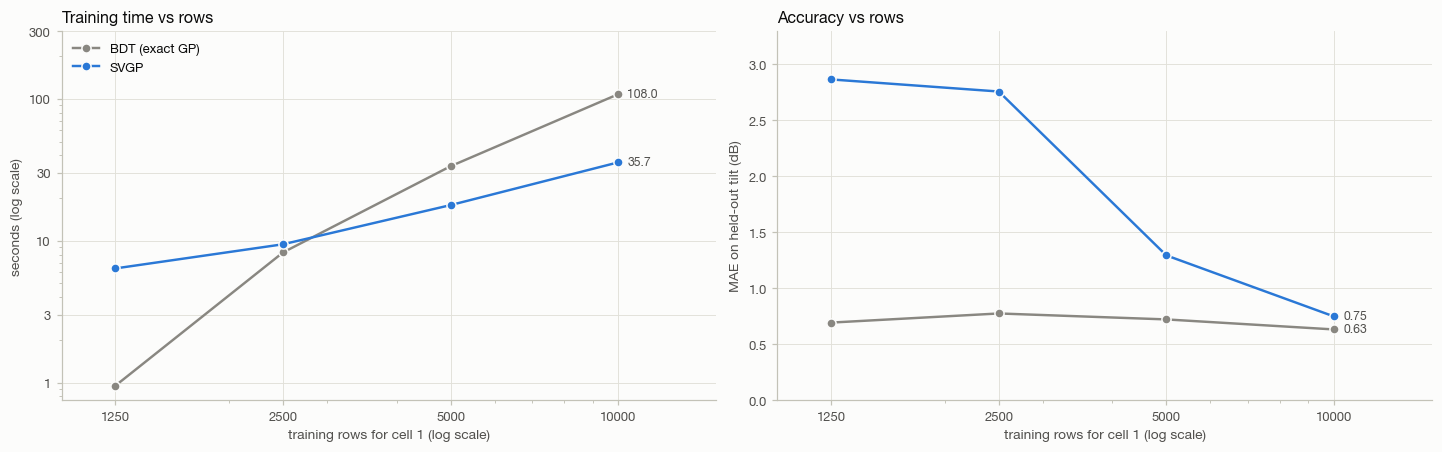

,model,rows,optimiser steps,train s,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage
0,SVGP,1250,200,6.386,2.865,3.396,4.739,6.231,-0.088,0.931,0.916,1.000
1,BDT (exact GP),1250,100,0.952,0.693,1.050,1.147,1.576,-0.337,0.993,0.937,1.000
2,SVGP,2500,300,9.449,2.757,3.325,4.504,6.382,0.016,0.934,0.773,0.993
3,BDT (exact GP),2500,100,8.274,0.775,1.165,1.282,1.650,-0.499,0.992,0.789,0.994
4,SVGP,5000,500,17.851,1.294,1.634,2.259,3.153,-0.179,0.984,0.737,0.968
5,BDT (exact GP),5000,100,33.544,0.722,0.973,1.185,1.635,-0.390,0.994,0.790,0.989
6,SVGP,10000,1000,35.711,0.748,0.963,1.308,1.760,-0.340,0.994,0.683,0.962
7,BDT (exact GP),10000,100,107.967,0.632,0.793,1.120,1.475,-0.337,0.996,0.898,0.999


In [22]:
pool = pd.concat([data[s][data[s].cell_id == FOCUS_CELL] for s in TRAIN_SIMS]).sample(frac=1, random_state=SEED)
scaling = []
for n in [1250, 2500, 5000, 10000]:
    rows = pool.iloc[:n].reset_index(drop=True)
    # wall time on a shared laptop is noisy, so each point's time is the faster of two identical runs
    runs = [svgp_twin([rows]) for _ in range(2)]
    twin, loss, secs = runs[0][0], runs[0][1], min(r[2] for r in runs)
    (mean,), (std,) = svgp_predict(twin, [focus_test])
    scaling.append({"model": "SVGP", "rows": n, "optimiser steps": int(np.isfinite(loss[0]).sum()) * int(np.ceil(n / 1024)),
                    "train s": secs, **kpis(focus_test[Y_COLUMN], mean, std)})
    runs = [bdt_twin(rows) for _ in range(2)]
    twin, secs = runs[0][0], min(r[1] for r in runs)
    mean, std = bdt_predict(twin, focus_test)
    scaling.append({"model": "BDT (exact GP)", "rows": n, "optimiser steps": 100, "train s": secs,
                    **kpis(focus_test[Y_COLUMN], mean, std)})
scaling = pd.DataFrame(scaling)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for ax, col, title, ylabel in [(axes[0], "train s", "Training time vs rows", "seconds (log scale)"),
                               (axes[1], "MAE (dB)", "Accuracy vs rows", "MAE on held-out tilt (dB)")]:
    for model, g in scaling.groupby("model"):
        ax.plot(g.rows, g[col], color=MODEL_COLOR[model], marker="o", ms=6, markeredgecolor=SURFACE, label=model)
        last = g.iloc[-1]
        ax.annotate(f"{last[col]:.1f}" if col == "train s" else f"{last[col]:.2f}", (last.rows, last[col]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK_2)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, scaling.rows.unique().tolist())
    ax.set_xlim(scaling.rows.min() * 0.8, scaling.rows.max() * 1.5)
    ax.set_xlabel(f"training rows for cell {FOCUS_CELL} (log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
axes[0].set_yscale("log")
plain_log_axis(axes[0].yaxis, [1, 3, 10, 30, 100, 300])
axes[1].set_ylim(0, scaling["MAE (dB)"].max() * 1.15)
axes[0].legend(loc="upper left")
plt.show()
scaling.round(3)

**What to notice.**
- **Time:** the SVGP grows linearly with rows and the exact GP much faster. They cross between 2,500 and 5,000 rows. At 10,000 rows the SVGP trains about 3× faster (36 s vs 108 s here).
- **Accuracy:** with its default settings the SVGP needs the rows to get enough steps. It is poor below 5,000 rows, and at 10,000 rows it is within about 0.1 dB of the exact GP (0.75 vs 0.63 dB).

## 12 · The main knob: inducing points

More inducing points give the twin more capacity to represent fine structure such as the antenna lobe. They also cost more: each step involves an M × M Cholesky factorisation. The focus cell's twin is retrained with M from 50 to 1,000, using the §5 batch size, and scored on the held-out tilt.

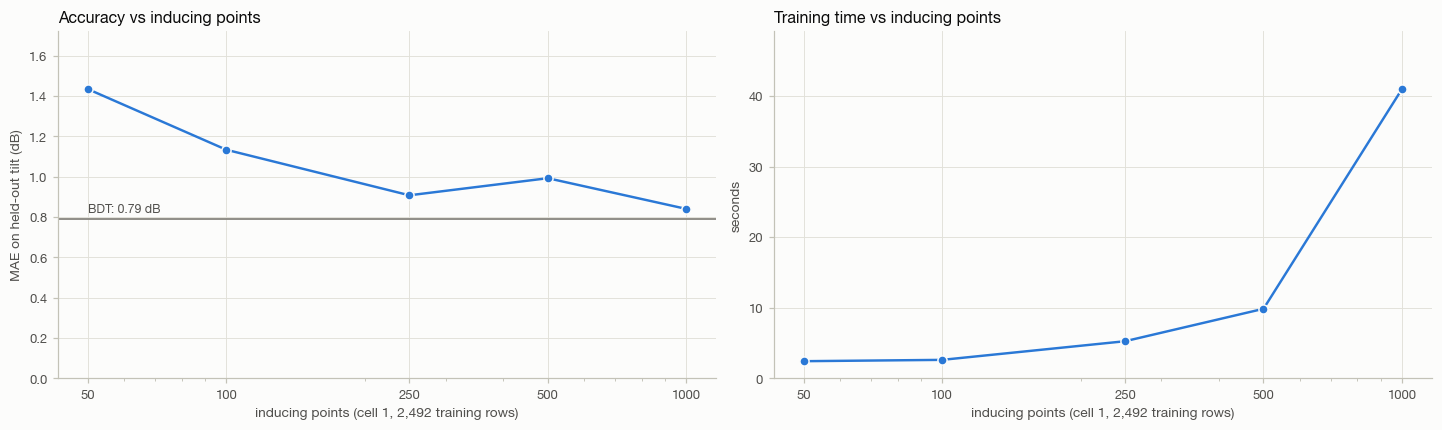

,inducing points,train s,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage
0,50,2.409,1.435,1.820,2.495,3.400,-0.206,0.980,0.719,0.973
1,100,2.597,1.134,1.654,1.954,2.652,-0.484,0.984,0.736,0.963
2,250,5.239,0.908,1.618,1.532,2.239,-0.376,0.984,0.756,0.970
3,500,9.834,0.993,1.628,1.807,2.420,-0.444,0.984,0.672,0.942
4,1000,40.963,0.840,1.306,1.516,2.106,-0.342,0.990,0.713,0.953


In [23]:
inducing_runs = []
for m in [50, 100, 250, 500, 1000]:
    twin, loss, secs = svgp_twin([focus_train], num_inducing=m, **SVGP_KW)
    (mean,), (std,) = svgp_predict(twin, [focus_test])
    inducing_runs.append({"inducing points": m, "train s": secs, **kpis(focus_test[Y_COLUMN], mean, std)})
inducing_runs = pd.DataFrame(inducing_runs)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
for ax, col, title, ylabel in [(axes[0], "MAE (dB)", "Accuracy vs inducing points", "MAE on held-out tilt (dB)"),
                               (axes[1], "train s", "Training time vs inducing points", "seconds")]:
    ax.plot(inducing_runs["inducing points"], inducing_runs[col], color=MODEL_COLOR["SVGP"], marker="o", ms=6,
            markeredgecolor=SURFACE)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, inducing_runs["inducing points"].tolist())
    ax.set_xlabel(f"inducing points (cell {FOCUS_CELL}, {len(focus_train):,} training rows)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(0, inducing_runs[col].max() * 1.2)
axes[0].axhline(bdt_focus["MAE (dB)"], color=MODEL_COLOR["BDT (exact GP)"], lw=1.2)
axes[0].annotate(f"BDT: {bdt_focus['MAE (dB)']:.2f} dB", (inducing_runs["inducing points"].min(), bdt_focus["MAE (dB)"]),
                 xytext=(0, 5), textcoords="offset points", fontsize=8, color=INK_2)
plt.show()
inducing_runs.round(3)

**What to notice.** Below about 250 inducing points the twin loses the antenna lobe (1.1–1.4 dB). From 250 up, accuracy stays within 0.84–0.99 dB, and the differences between 250, 500 and 1,000 are within the run-to-run noise of SVGP training (§5). Time grows about 8× from 250 to 1,000. For this footprint, 250 is enough.

## 13 · What-if: sweep the tilt

Three locations on cell 1's boresight are swept continuously from 0° to 20°. The dots are the simulator's truth at the five configured tilts; the hollow dot is the held-out 10° run. Because the batched model predicts all cells at once, a single-cell query passes empty frames for the other cells.

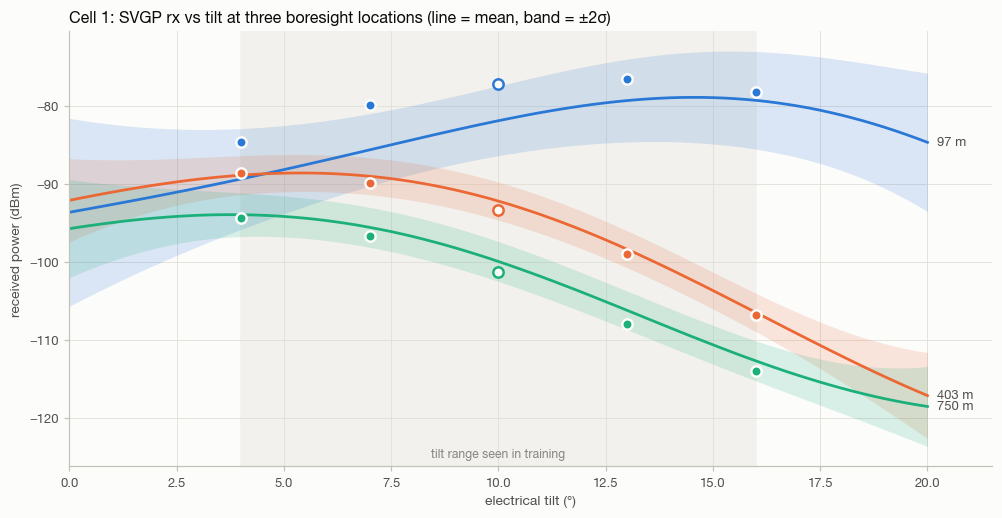

In [24]:
def predict_cell(cell_id, rows):
    """Query one cell of the batched SVGP: the other cells get empty frames."""
    frames = [rows if c == cell_id else rows.iloc[:0] for c in CELLS]
    means, stds = svgp_predict(svgp, frames)
    return means[CELLS.index(cell_id)], stds[CELLS.index(cell_id)]


TILT_GRID = np.arange(0, 20.01, 0.25)
boresight = focus_test[np.minimum(focus_test.relative_bearing, 360 - focus_test.relative_bearing) <= 8]
probe_dist = [100, 400, 750]
probes = [boresight.iloc[(np.expm1(boresight.log_distance) - d).abs().argmin()] for d in probe_dist]

fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
ax.axvspan(min(TILT.values()), max(TILT.values()), color=TILE, zorder=0)
ax.text(np.mean(list(TILT.values())), 0.02, "tilt range seen in training", transform=ax.get_xaxis_transform(),
        ha="center", fontsize=8, color=MUTED)
for probe, color in zip(probes, SLOTS):
    sweep = pd.DataFrame([probe] * len(TILT_GRID)).reset_index(drop=True)
    sweep["cell_el_deg"] = TILT_GRID
    mean, std = predict_cell(FOCUS_CELL, sweep)
    ax.fill_between(TILT_GRID, mean - 2 * std, mean + 2 * std, color=color, alpha=0.16, linewidth=0)
    ax.plot(TILT_GRID, mean, color=color, lw=1.8)
    for sim in SIMS:
        df = data[sim]
        truth = df.loc[(df.cell_id == FOCUS_CELL) & (df.ix == probe.ix) & (df.iy == probe.iy), Y_COLUMN].iloc[0]
        held_out = sim == TEST_SIM
        ax.scatter(TILT[sim], truth, s=46, zorder=4, linewidth=1.6,
                   facecolor=SURFACE if held_out else color, edgecolor=color if held_out else SURFACE)
    ax.annotate(f"{np.expm1(probe.log_distance):.0f} m", (TILT_GRID[-1], mean[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK_2)
ax.set_xlim(0, 21.5)
ax.set_xlabel("electrical tilt (°)")
ax.set_ylabel("received power (dBm)")
ax.set_title(f"Cell {FOCUS_CELL}: SVGP rx vs tilt at three boresight locations (line = mean, band = ±2σ)")
plt.show()

**What to notice.** The SVGP learns both tilt responses: rising then flat near the mast, falling far out. It lands close to the held-out 10° points at 400 m and 750 m. As with the BDT, the location near the mast is the hardest, and the ±2σ bands widen outside the 4–16° training range.

## 14 · Network KPIs from the twin, tilt by tilt

A coverage optimiser asks the twin for network KPIs under each candidate configuration. The SVGP predicts the full network at each of the five tilts. The four training tilts are only partially in-sample (20% of their rows were used), and 10° is fully held out.

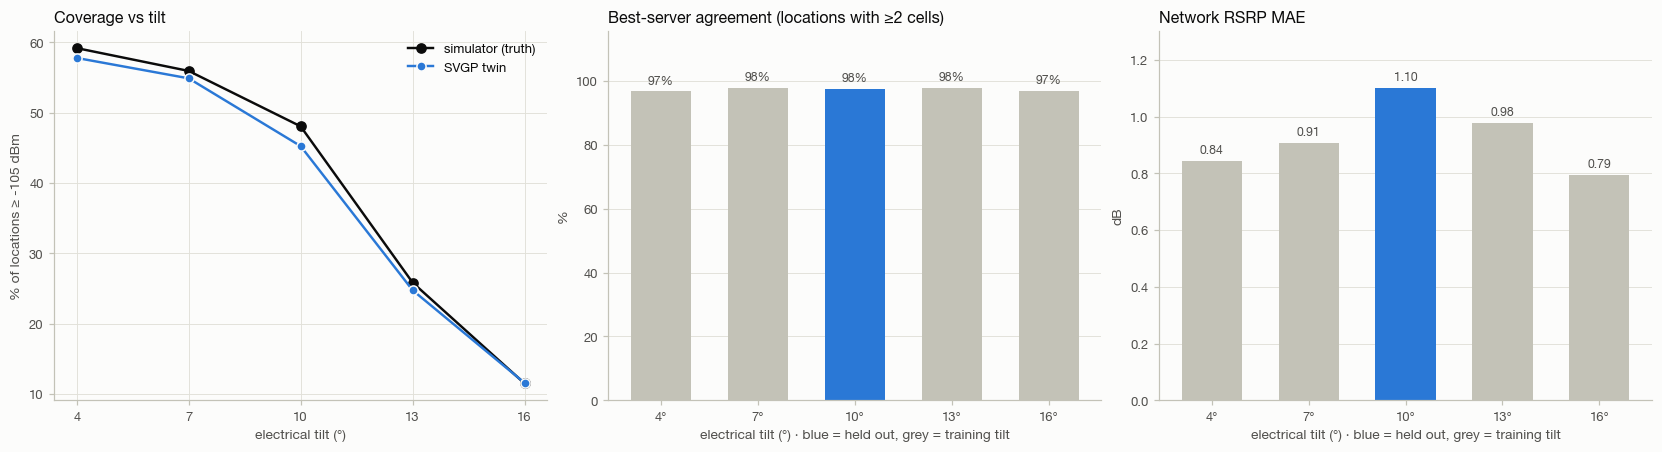

,tilt (°),held out,true coverage,twin coverage,best-server agreement,network MAE (dB)
0,4,False,0.592,0.578,0.968,0.844
1,7,False,0.559,0.549,0.979,0.907
2,10,True,0.481,0.452,0.975,1.103
3,13,False,0.259,0.248,0.980,0.978
4,16,False,0.115,0.116,0.969,0.795


In [25]:
per_tilt = []
for sim in SIMS:
    nc = network_compare(predict_all(data[sim]))
    multi_sim = nc[nc.n_cells >= 2]
    per_tilt.append(
        {
            "tilt (°)": TILT[sim],
            "held out": sim == TEST_SIM,
            "true coverage": (nc.true_rsrp >= COVERAGE_DBM).mean(),
            "twin coverage": (nc.pred_rsrp >= COVERAGE_DBM).mean(),
            "best-server agreement": (multi_sim.true_server == multi_sim.pred_server).mean(),
            "network MAE (dB)": np.abs(nc.pred_rsrp - nc.true_rsrp).mean(),
        }
    )
per_tilt = pd.DataFrame(per_tilt)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
ax = axes[0]
ax.plot(per_tilt["tilt (°)"], 100 * per_tilt["true coverage"], color=INK, marker="o", ms=6, label="simulator (truth)")
ax.plot(per_tilt["tilt (°)"], 100 * per_tilt["twin coverage"], color=MODEL_COLOR["SVGP"], marker="o", ms=6,
        markeredgecolor=SURFACE, label="SVGP twin")
ax.set_xticks(per_tilt["tilt (°)"])
ax.set_xlabel("electrical tilt (°)")
ax.set_ylabel(f"% of locations ≥ {COVERAGE_DBM} dBm")
ax.set_title("Coverage vs tilt")
ax.legend()
bar_colors = [MODEL_COLOR["SVGP"] if h else AXIS for h in per_tilt["held out"]]
for ax, col, title, fmt in [
    (axes[1], "best-server agreement", "Best-server agreement (locations with ≥2 cells)", "{:.0%}"),
    (axes[2], "network MAE (dB)", "Network RSRP MAE", "{:.2f}"),
]:
    values = per_tilt[col] * (100 if col == "best-server agreement" else 1)
    bars = ax.bar(per_tilt["tilt (°)"].astype(str) + "°", values, color=bar_colors, width=0.62)
    ax.bar_label(bars, labels=[fmt.format(v) for v in per_tilt[col]], padding=3, fontsize=8, color=INK_2)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, values.max() * 1.18)
    ax.set_xlabel("electrical tilt (°) · blue = held out, grey = training tilt")
axes[1].set_ylabel("%")
axes[2].set_ylabel("dB")
plt.show()
per_tilt.round(3)

**What to notice.** Coverage tracks the simulator within about 3 points at every tilt, best-server agreement is 97–98%, and network MAE is 0.8–1.1 dB. That is slightly behind the BDT's figures in [bayesian_digital_twin.ipynb](bayesian_digital_twin.ipynb).

## 15 · Where does it break? Leave-one-tilt-out

Each tilt in turn is held out, and the focus cell's twin is retrained on 20% of the other four runs: the SVGP with the §5 configuration, and the BDT next to it. Holding out 7°, 10° or 13° is **interpolation**; holding out 4° or 16° is **extrapolation** past the edge of the training range. If mean σ rises with the error, the twin flags its own extrapolation instead of failing silently.

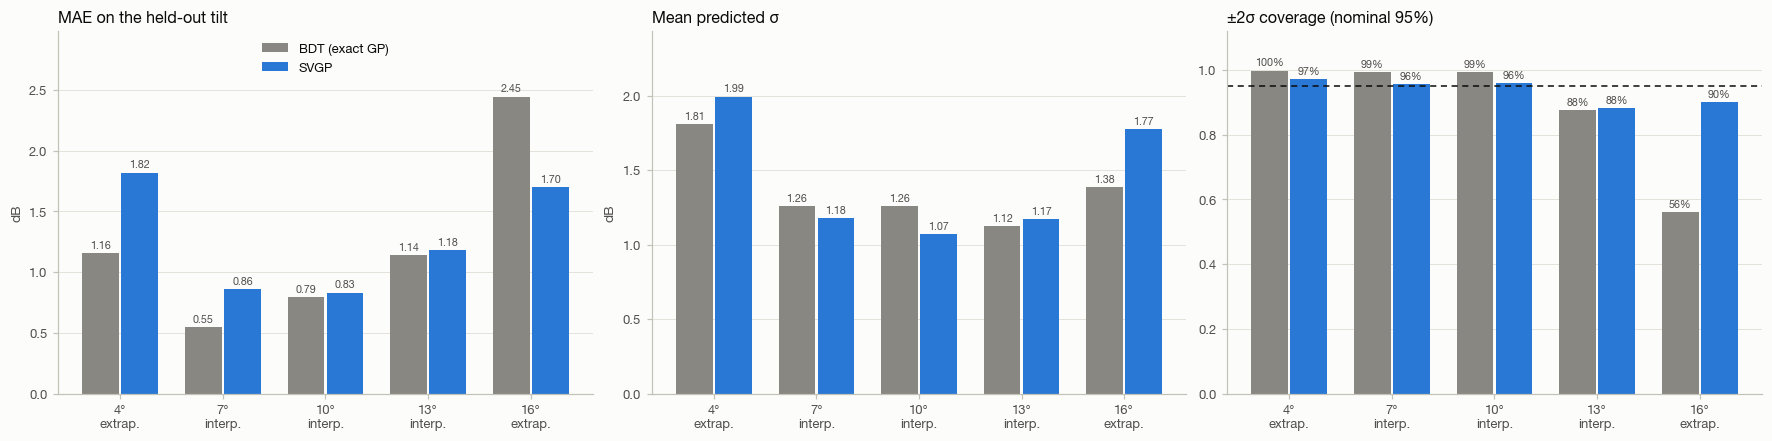

,model,held-out tilt (°),regime,MAE (dB),RMSE (dB),P85 |err| (dB),P95 |err| (dB),bias (dB),R²,±1σ coverage,±2σ coverage,mean σ (dB)
0,SVGP,4,extrapolation,1.819,2.379,2.849,3.580,-1.463,0.958,0.568,0.971,1.993
1,BDT (exact GP),4,extrapolation,1.158,1.702,1.967,2.712,-0.979,0.978,0.805,0.999,1.809
2,SVGP,7,interpolation,0.859,1.474,1.382,2.407,0.214,0.985,0.786,0.956,1.177
3,BDT (exact GP),7,interpolation,0.548,1.136,0.888,1.382,0.051,0.991,0.929,0.994,1.260
4,SVGP,10,interpolation,0.831,1.275,1.432,1.978,-0.401,0.990,0.714,0.960,1.070
5,BDT (exact GP),10,interpolation,0.793,1.179,1.289,1.711,-0.509,0.992,0.817,0.994,1.259
6,SVGP,13,interpolation,1.180,1.673,2.090,3.215,0.456,0.986,0.597,0.883,1.173
7,BDT (exact GP),13,interpolation,1.139,1.557,1.996,2.929,0.576,0.987,0.583,0.877,1.125
8,SVGP,16,extrapolation,1.702,2.192,2.967,3.905,-0.513,0.974,0.559,0.900,1.774
9,BDT (exact GP),16,extrapolation,2.446,3.054,4.349,5.566,-2.100,0.949,0.363,0.560,1.385


In [26]:
loto = []
for held_out in SIMS:
    rows_in = pd.concat([data[s][data[s].cell_id == FOCUS_CELL].sample(frac=P_TRAIN, random_state=SEED)
                         for s in SIMS if s != held_out]).reset_index(drop=True)
    rows_out = data[held_out][data[held_out].cell_id == FOCUS_CELL]
    tilt = TILT[held_out]
    regime = "extrapolation" if tilt in (min(TILT.values()), max(TILT.values())) else "interpolation"
    twin, _, _ = svgp_twin([rows_in], **SVGP_KW)
    (mean,), (std,) = svgp_predict(twin, [rows_out])
    loto.append({"model": "SVGP", "held-out tilt (°)": tilt, "regime": regime,
                 **kpis(rows_out[Y_COLUMN], mean, std), "mean σ (dB)": std.mean()})
    twin, _ = bdt_twin(rows_in)
    mean, std = bdt_predict(twin, rows_out)
    loto.append({"model": "BDT (exact GP)", "held-out tilt (°)": tilt, "regime": regime,
                 **kpis(rows_out[Y_COLUMN], mean, std), "mean σ (dB)": std.mean()})
loto = pd.DataFrame(loto)

tilts = sorted(loto["held-out tilt (°)"].unique())
tick_labels = [f"{t}°\n{'extrap.' if t in (min(tilts), max(tilts)) else 'interp.'}" for t in tilts]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.9), layout="constrained")
width = 0.38
for ax, col, title, fmt in [(axes[0], "MAE (dB)", "MAE on the held-out tilt", "{:.2f}"),
                            (axes[1], "mean σ (dB)", "Mean predicted σ", "{:.2f}"),
                            (axes[2], "±2σ coverage", "±2σ coverage (nominal 95%)", "{:.0%}")]:
    for k, model in enumerate(MODEL_COLOR):
        values = loto[loto.model == model].set_index("held-out tilt (°)").loc[tilts, col]
        bars = ax.bar(np.arange(len(tilts)) + (k - 0.5) * width, values, width=width * 0.94, color=MODEL_COLOR[model], label=model)
        ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=2, fontsize=7, color=INK_2)
    ax.set_xticks(np.arange(len(tilts)))
    ax.set_xticklabels(tick_labels)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, loto[col].max() * 1.22)
axes[2].axhline(0.95, color=INK, lw=1, ls=(0, (4, 3)))
axes[2].set_ylim(0, 1.12)
axes[0].set_ylabel("dB")
axes[1].set_ylabel("dB")
axes[0].legend(loc="upper center")
plt.show()
loto.round(3)

**What to notice.**
- **Interpolating** costs the SVGP 0.8–1.2 dB, a little more than the BDT, most visibly at 7°.
- **Extrapolating to 16°** is where the SVGP does better. Its MAE is lower (1.70 vs 2.45 dB), and its σ grows with the error, so 90% of truths stay inside ±2σ against the BDT's 56%. The SVGP's coverage here moved between 79% and 97% across three runs while this notebook was built; the BDT's was 56% every time.
- **Extrapolating to 4°** is harder for the SVGP (1.82 vs 1.16 dB), but its σ again rises to cover the error.

## 16 · Adapting to a new tilt: the streaming update

**Scenario.** Cell 1's twin was trained while the network ran at 4–13°. The operator moves to 16°, outside anything the twin has seen, and fresh measurements arrive. Three ways to adapt:
- **SVGP streaming update.** `update_trained_gpmodel` runs a short training loop (20 epochs by default) on the **new rows only**, with the inducing points frozen. The engine documents it as approximate, not equivalent to a GP fantasy update.
- **SVGP full retrain** on the old and new rows together.
- **BDT fantasy update** for reference. It conditions the exact GP on the new rows and keeps its hyperparameters.

The 16° rows are split into an update pool and a disjoint evaluation set. One more check matters for a streaming method: does the twin still know the tilts it was trained on? That is scored on the 10° run, which the base twin did see a 20% sample of.

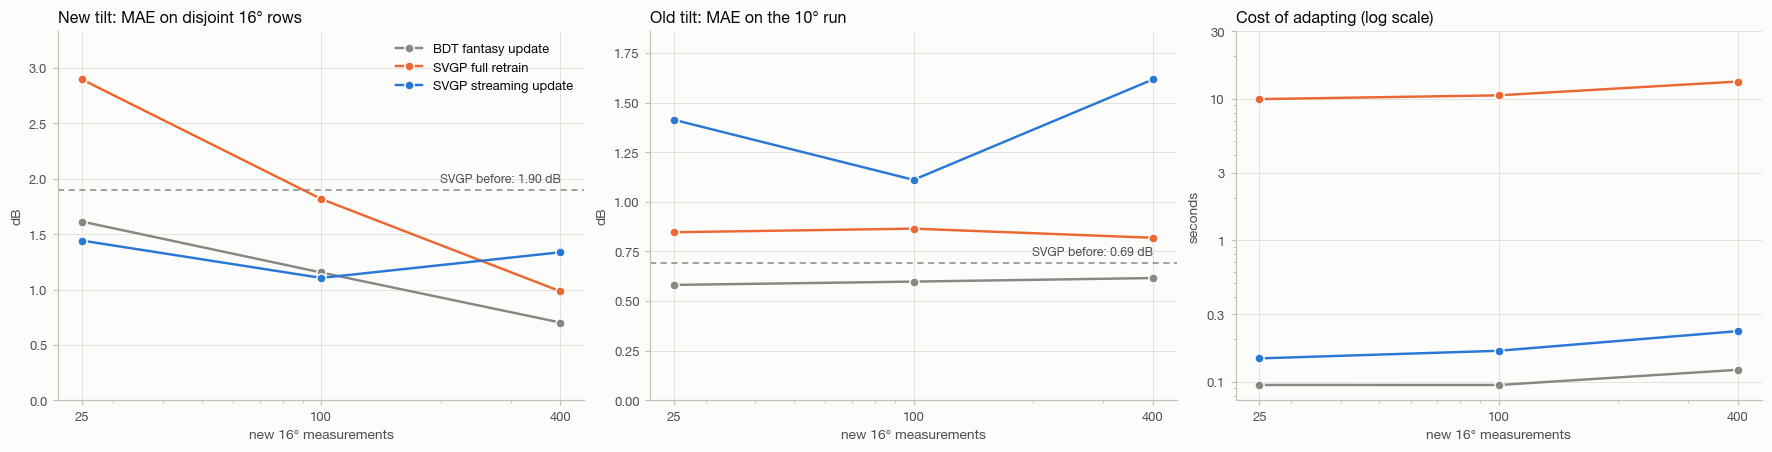

,method,new rows,16° MAE (dB),16° ±2σ coverage,10° MAE (dB),seconds
0,before any 16° data (SVGP),0,1.899,0.958,0.691,0.000
1,before any 16° data (BDT),0,2.451,0.566,0.702,0.000
2,SVGP streaming update,25,1.442,0.938,1.413,0.146
3,SVGP full retrain,25,2.898,0.482,0.847,9.960
4,BDT fantasy update,25,1.614,0.699,0.581,0.095
5,SVGP streaming update,100,1.105,0.945,1.111,0.166
6,SVGP full retrain,100,1.818,0.870,0.865,10.594
7,BDT fantasy update,100,1.154,0.888,0.598,0.095
8,SVGP streaming update,400,1.337,0.893,1.617,0.228
9,SVGP full retrain,400,0.984,0.952,0.819,13.259


In [27]:
NEW_SIM = SIMS[-1]  # 16°: beyond the base twin's tilt range
OLD_SIM = TEST_SIM  # 10°: inside it
base_rows = pd.concat([data[s][data[s].cell_id == FOCUS_CELL].sample(frac=P_TRAIN, random_state=SEED)
                       for s in SIMS[:-1]]).reset_index(drop=True)
new_rows = data[NEW_SIM][data[NEW_SIM].cell_id == FOCUS_CELL].sample(frac=1, random_state=SEED)
upd_pool = new_rows.iloc[: len(new_rows) // 2].reset_index(drop=True)
holdout = new_rows.iloc[len(new_rows) // 2:].reset_index(drop=True)
old_rows = data[OLD_SIM][data[OLD_SIM].cell_id == FOCUS_CELL].reset_index(drop=True)


def score(predict, method, n, secs):
    (mean_new, std_new), (mean_old, _) = predict(holdout), predict(old_rows)
    new = kpis(holdout[Y_COLUMN], mean_new, std_new)
    return {"method": method, "new rows": n, "16° MAE (dB)": new["MAE (dB)"], "16° ±2σ coverage": new["±2σ coverage"],
            "10° MAE (dB)": np.abs(mean_old - old_rows[Y_COLUMN]).mean(), "seconds": secs}


def svgp_single(twin):
    return lambda rows: tuple(a[0] for a in svgp_predict(twin, [rows]))


def bdt_single(twin):
    return lambda rows: bdt_predict(twin, rows)


svgp_base, _, svgp_base_secs = svgp_twin([base_rows], **SVGP_KW)
bdt_base, bdt_base_secs = bdt_twin(base_rows)
adapt = [score(svgp_single(svgp_base), "before any 16° data (SVGP)", 0, 0.0),
         score(bdt_single(bdt_base), "before any 16° data (BDT)", 0, 0.0)]
for n in [25, 100, 400]:
    new = upd_pool.iloc[:n]
    twin = copy.deepcopy(svgp_base)
    start = time.perf_counter()
    twin.update_trained_gpmodel([new], SVGPUpdateConfig())
    adapt.append(score(svgp_single(twin), "SVGP streaming update", n, time.perf_counter() - start))
    twin, _, secs = svgp_twin([pd.concat([base_rows, new], ignore_index=True)], **SVGP_KW)
    adapt.append(score(svgp_single(twin), "SVGP full retrain", n, secs))
    twin = copy.deepcopy(bdt_base)
    start = time.perf_counter()
    twin.update_trained_gpmodel([new])
    adapt.append(score(bdt_single(twin), "BDT fantasy update", n, time.perf_counter() - start))
adapt = pd.DataFrame(adapt)

ADAPT_COLOR = {"SVGP streaming update": SLOTS[0], "SVGP full retrain": SLOTS[1], "BDT fantasy update": MODEL_COLOR["BDT (exact GP)"]}
fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
for ax, col, title in [(axes[0], "16° MAE (dB)", "New tilt: MAE on disjoint 16° rows"),
                       (axes[1], "10° MAE (dB)", "Old tilt: MAE on the 10° run"),
                       (axes[2], "seconds", "Cost of adapting (log scale)")]:
    for method, g in adapt[adapt["new rows"] > 0].groupby("method"):
        ax.plot(g["new rows"], g[col], color=ADAPT_COLOR[method], marker="o", ms=6, markeredgecolor=SURFACE, label=method)
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis, [25, 100, 400])
    ax.set_xlabel("new 16° measurements")
    ax.set_title(title)
for ax, col in [(axes[0], "16° MAE (dB)"), (axes[1], "10° MAE (dB)")]:
    before = adapt.loc[adapt.method == "before any 16° data (SVGP)", col].iloc[0]
    ax.axhline(before, color=MUTED, lw=1, ls=(0, (4, 3)))
    ax.annotate(f"SVGP before: {before:.2f} dB", (400, before), xytext=(0, 5), textcoords="offset points",
                ha="right", fontsize=8, color=INK_2)
    ax.set_ylim(0, adapt[col].max() * 1.15)
    ax.set_ylabel("dB")
axes[2].set_yscale("log")
plain_log_axis(axes[2].yaxis, [0.1, 0.3, 1, 3, 10, 30])
axes[2].set_ylabel("seconds")
axes[0].legend(loc="upper right")
plt.show()
adapt.round(3)

**What to notice.**
- **The streaming update helps the new tilt.** 100 new rows cut the 16° error from 1.9 to 1.1 dB in a fraction of a second. More rows did not keep helping here (1.34 dB at 400).
- **It forgets.** It trains on the new rows only, so the error on 10°, a tilt the twin was trained on, rises from 0.69 to 1.62 dB after 400 rows (2.3×). The BDT's fantasy update conditions on the new rows exactly, and its 10° error stays flat.
- **A full SVGP retrain keeps 10°** (0.82 dB at 400 rows) and reaches 0.98 dB at 16°, at about 50× the update's cost. With only 25–100 new rows it does worse at 16° than the streaming update.
- Recipe: stream small updates to adapt to a new configuration, then retrain on all the data before relying on the twin elsewhere.

## 17 · Ship it: checkpoint round-trip and scorecard

`SVGPDigitalTwin.save` writes one `torch.save` checkpoint for the whole batched model: inducing points, variational state, kernel, likelihood, normalisation statistics and cell ids. `SVGPDigitalTwin.load` reads it back in PyTorch's weights-only mode.

In [28]:
with tempfile.TemporaryDirectory() as tmp:
    ckpt = f"{tmp}/svgp_twin.pt"
    svgp.save(ckpt)
    ckpt_mb = Path(ckpt).stat().st_size / 1e6
    reloaded = SVGPDigitalTwin.load(ckpt, map_location="cpu")

frames = [test_df[test_df.cell_id == c][X_COLUMNS + ["cell_id"]] for c in CELLS]
before = np.concatenate(svgp_predict(svgp, frames)[0])
after = np.concatenate(svgp_predict(reloaded, frames)[0])
max_diff = np.abs(after - before).max()
assert max_diff < 1e-3, max_diff
print(f"checkpoint: {ckpt_mb:.2f} MB for {len(CELLS)} cells · max prediction drift after reload: {max_diff:.1e} dB ✓")

checkpoint: 5.05 MB for 5 cells · max prediction drift after reload: 0.0e+00 dB ✓


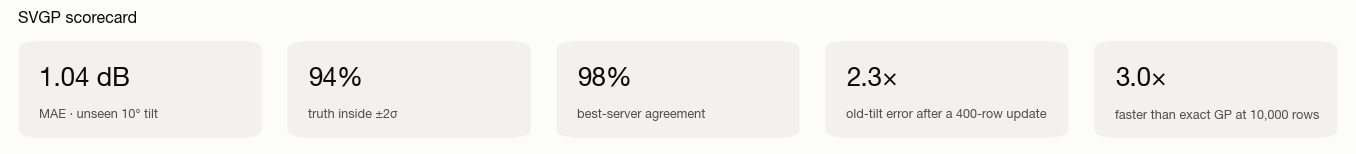

area,KPI,SVGP,BDT (exact GP)
Accuracy,MAE on held-out 10° tilt (per-cell rows),1.04 dB,0.88 dB
Accuracy,RMSE / P95 |error|,1.60 / 2.68 dB,1.37 / 2.13 dB
Accuracy,Bias,-0.50 dB,-0.50 dB
Network,Network RSRP MAE (strongest cell),1.10 dB,0.94 dB
Network,Coverage ≥ -105 dBm (truth 48.1%),45.2%,45.7%
Network,Best-server agreement (≥2 cells),97.5%,98.3%
Uncertainty,±1σ / ±2σ coverage (nominal 68% / 95%),66% / 94%,76% / 98%
Generalisation,MAE interpolating vs extrapolating tilt (cell 1),0.96 vs 1.76 dB,0.83 vs 1.80 dB
Generalisation,±2σ coverage extrapolating to 16° (cell 1),90%,56%
Training,"Default config (batch 1,024) MAE, cell 1",2.58 dB,0.79 dB


In [29]:
streamed = adapt[(adapt.method == "SVGP streaming update") & (adapt["new rows"] == 400)].iloc[0]
svgp_before = adapt[adapt.method == "before any 16° data (SVGP)"].iloc[0]
bdt_before = adapt[adapt.method == "before any 16° data (BDT)"].iloc[0]
bdt_updated = adapt[(adapt.method == "BDT fantasy update") & (adapt["new rows"] == 400)].iloc[0]
big = scaling[scaling.rows == scaling.rows.max()].set_index("model")
bdt_net = network_compare(test_df.drop(columns=["pred_dbm", "pred_std_db"]).rename(
    columns={"bdt_dbm": "pred_dbm", "bdt_std_db": "pred_std_db"}))
bdt_multi = bdt_net[bdt_net.n_cells >= 2]
stat_tiles(
    [
        (f"{overall['MAE (dB)']:.2f} dB", f"MAE · unseen {TILT[TEST_SIM]}° tilt"),
        (f"{overall['±2σ coverage']:.0%}", "truth inside ±2σ"),
        (f"{server_agreement:.0%}", "best-server agreement"),
        (f"{streamed['10° MAE (dB)'] / svgp_before['10° MAE (dB)']:.1f}×", "old-tilt error after a 400-row update"),
        (f"{big.loc['BDT (exact GP)', 'train s'] / big.loc['SVGP', 'train s']:.1f}×",
         f"faster than exact GP at {scaling.rows.max():,} rows"),
    ],
    title="SVGP scorecard",
)
bdt_row, svgp_row = compare["BDT (exact GP)"], compare["SVGP"]
scorecard = pd.DataFrame(
    [
        ("Accuracy", f"MAE on held-out {TILT[TEST_SIM]}° tilt (per-cell rows)", f"{svgp_row['MAE (dB)']:.2f} dB", f"{bdt_row['MAE (dB)']:.2f} dB"),
        ("Accuracy", "RMSE / P95 |error|", f"{svgp_row['RMSE (dB)']:.2f} / {svgp_row['P95 |err| (dB)']:.2f} dB",
         f"{bdt_row['RMSE (dB)']:.2f} / {bdt_row['P95 |err| (dB)']:.2f} dB"),
        ("Accuracy", "Bias", f"{svgp_row['bias (dB)']:+.2f} dB", f"{bdt_row['bias (dB)']:+.2f} dB"),
        ("Network", "Network RSRP MAE (strongest cell)", f"{kpi_table.loc['network RSRP (strongest cell)', 'MAE (dB)']:.2f} dB",
         f"{np.abs(bdt_net.pred_rsrp - bdt_net.true_rsrp).mean():.2f} dB"),
        ("Network", f"Coverage ≥ {COVERAGE_DBM} dBm (truth {true_cov:.1%})", f"{pred_cov:.1%}",
         f"{(bdt_net.pred_rsrp >= COVERAGE_DBM).mean():.1%}"),
        ("Network", "Best-server agreement (≥2 cells)", f"{server_agreement:.1%}",
         f"{(bdt_multi.true_server == bdt_multi.pred_server).mean():.1%}"),
        ("Uncertainty", "±1σ / ±2σ coverage (nominal 68% / 95%)",
         f"{svgp_row['±1σ coverage']:.0%} / {svgp_row['±2σ coverage']:.0%}", f"{bdt_row['±1σ coverage']:.0%} / {bdt_row['±2σ coverage']:.0%}"),
        ("Generalisation", "MAE interpolating vs extrapolating tilt (cell 1)",
         *[f"{loto[(loto.model == m) & (loto.regime == 'interpolation')]['MAE (dB)'].mean():.2f} vs "
           f"{loto[(loto.model == m) & (loto.regime == 'extrapolation')]['MAE (dB)'].mean():.2f} dB" for m in ["SVGP", "BDT (exact GP)"]]),
        ("Generalisation", f"±2σ coverage extrapolating to {max(TILT.values())}° (cell 1)",
         *[f"{loto[(loto.model == m) & (loto['held-out tilt (°)'] == max(TILT.values()))]['±2σ coverage'].iloc[0]:.0%}"
           for m in ["SVGP", "BDT (exact GP)"]]),
        ("Training", "Default config (batch 1,024) MAE, cell 1", f"{steps_runs.iloc[0]['MAE (dB)']:.2f} dB", f"{bdt_focus['MAE (dB)']:.2f} dB"),
        ("Cost", f"Training time, {len(CELLS)} cells × ~{int(np.mean([len(f) for f in train_frames])):,} rows",
         f"{svgp_secs:.1f} s", f"{sum(bdt_secs.values()):.1f} s"),
        ("Cost", f"Training time, cell 1 × {scaling.rows.max():,} rows", f"{big.loc['SVGP', 'train s']:.1f} s", f"{big.loc['BDT (exact GP)', 'train s']:.1f} s"),
        ("Cost", "Inference per 1k rows: first call / warm",
         f"{svgp_row['inference ms per 1k rows, first call']:.0f} / {svgp_row['inference ms per 1k rows, warm']:.0f} ms",
         f"{bdt_row['inference ms per 1k rows, first call']:.0f} / {bdt_row['inference ms per 1k rows, warm']:.0f} ms"),
        ("Adaptation", "16° MAE before → after a 400-row update (cell 1)",
         f"{svgp_before['16° MAE (dB)']:.2f} → {streamed['16° MAE (dB)']:.2f} dB",
         f"{bdt_before['16° MAE (dB)']:.2f} → {bdt_updated['16° MAE (dB)']:.2f} dB"),
        ("Adaptation", "10° MAE before → after that update (a tilt it was trained on)",
         f"{svgp_before['10° MAE (dB)']:.2f} → {streamed['10° MAE (dB)']:.2f} dB",
         f"{bdt_before['10° MAE (dB)']:.2f} → {bdt_updated['10° MAE (dB)']:.2f} dB"),
        ("Adaptation", "Update time, 400 rows", f"{streamed['seconds']:.2f} s", f"{bdt_updated['seconds']:.2f} s"),
        ("Footprint", "Saved model, 5 cells", f"{ckpt_mb:.2f} MB", f"{size_mb['BDT (exact GP)']:.2f} MB"),
    ],
    columns=["area", "KPI", "SVGP", "BDT (exact GP)"],
)
scorecard.style.hide(axis="index")

## Takeaways

- **Count optimiser steps, not epochs.** The defaults (batch 1,024, 100 epochs) give a 2,500-row cell 300 steps and underfit it badly (MAE 2.6 dB). About 1,000 steps (batch 256 here) brings the SVGP within about 0.15 dB of the exact GP.
- **Turn early stopping off** (`stopping_threshold=0`). On mini-batch losses it fires by chance, and one seed here stopped at epoch 50 with MAE 1.34 dB.
- **SVGP training is not repeatable run to run** on this data, even with the same seed. Compare configurations over more than one run.
- **Its σ is the more honest of the two twins.** Coverage is near nominal when interpolating, and when extrapolating to 16° it covers far more of the truth than the BDT (79–97% across runs vs 56%).
- **It pays off with data, not on this dataset.** Below about 2,500–5,000 rows per cell the exact GP is faster and more accurate. At 10,000 rows the SVGP trains about 3× faster for about 0.1 dB of accuracy.
- **About 250 inducing points are enough** for this footprint; more costs time for no measurable gain.
- **The streaming update forgets.** Use it to adapt quickly, then retrain on all the data.
- **The checkpoint is about 20× larger** than the BDT's pickle (5 MB for 5 cells), and it round-trips exactly.

**Next steps.** A patience-based early-stopping rule in the engine, and an update that keeps the old data's influence (the engine lists a Bui–Nguyen–Turner style update as future work). See [README-SVGP.md](../README-SVGP.md).